Loaded 18 alignment records
Reference range: 120588854 - 148964865

Parsed contig names:
h1tg000041l_chr1_RagTag_12 -> 12
h1tg000053l_chr1_RagTag_13 -> 13
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000055l_chr1_RagTag_16 -> 16


,index,contig_name,left_mark,right_mark,start_pos,end_pos,orientation,ref_start,ref_end
0,16,h1tg000041l_chr1_RagTag_12,False,True,53147410,54440645,+,120588854,121812712
1,57,h1tg000053l_chr1_RagTag_13,True,False,2650341,2679661,+,124094512,124123494
2,63,h1tg000056l_chr1_RagTag_14,True,False,669596,681715,-,124741565,124753686
3,65,h1tg000056l_chr1_RagTag_14,False,True,36640,55799,-,125000313,125019457
4,68,h1tg000055l_chr1_RagTag_16,True,False,16790,37599,+,125372314,125393114


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.patches as patches


def parse_alignment_data(data_text):
    """
    Parse alignment data from text format.
    Expected format: index contig_name left_mark right_mark start_pos end_pos | orientation ref_start ref_end
    """
    lines = data_text.strip().split('\n')
    data = []
    
    for line in lines:
        if not line.strip():
            continue
            
        parts = line.split()
        if len(parts) >= 9:
            index = int(parts[0])
            contig_name = parts[1]
            left_mark = parts[2] == 'True'
            right_mark = parts[3] == 'True'
            start_pos = int(parts[4])
            end_pos = int(parts[5])
            orientation = parts[7]  # + or -
            ref_start = int(parts[8])
            ref_end = int(parts[9])
            
            data.append({
                'index': index,
                'contig_name': contig_name,
                'left_mark': left_mark,
                'right_mark': right_mark,
                'start_pos': start_pos,
                'end_pos': end_pos,
                'orientation': orientation,
                'ref_start': ref_start,
                'ref_end': ref_end
            })
    
    return pd.DataFrame(data)

def parse_contig_name(contig_name):
    """
    Parse contig name to get the last part after '_'
    Example: h1tg000029l_chr1_RagTag_10 -> 10
    """
    parts = contig_name.split('_')
    return parts[-1] if parts else contig_name

def calculate_y_positions(df, spacing_type='fixed', spacing=1.5):
    """
    Calculate y-positions for contigs.
    
    Parameters:
    - spacing_type: 'fixed' for uniform spacing, 'smart' for overlap avoidance
    - spacing: vertical distance between segments (for fixed spacing)
    """
    y_positions = {}
    
    if spacing_type == 'fixed':
        # Fixed spacing: each segment gets a consistent vertical position
        for i, (idx, row) in enumerate(df.iterrows()):
            y_positions[idx] = i * spacing
    
    else:  # 'smart' spacing
        # Original overlap avoidance logic
        for idx, row in df.iterrows():
            # Start with the index as base position
            base_y = row['index']
            
            # Check for overlaps with previously placed contigs
            overlap_found = True
            attempts = 0
            max_attempts = 10
            
            while overlap_found and attempts < max_attempts:
                overlap_found = False
                
                for prev_idx, prev_row in df.iterrows():
                    if prev_idx >= idx:
                        continue
                        
                    prev_y = y_positions[prev_idx]
                    
                    # Check if there's overlap in both x and y
                    x_overlap = (row['ref_start'] < prev_row['ref_end'] and 
                               row['ref_end'] > prev_row['ref_start'])
                    y_overlap = abs(base_y - prev_y) < 1.0
                    
                    if x_overlap and y_overlap:
                        overlap_found = True
                        base_y += 1.0
                        break
                
                attempts += 1
            
            y_positions[idx] = base_y
    
    return y_positions

def visualize_alignments(df, output_file=None, figsize=(15, 10), dpi=300, show_labels=True, 
                        spacing_type='fixed', spacing=1.5, Title=None):
    """
    Create visualization of alignment data with improved label handling.
    Red dots for left boundaries, blue dots for right boundaries.
    
    Parameters:
    - spacing_type: 'fixed' for uniform spacing, 'smart' for overlap avoidance
    - spacing: vertical distance between segments (for fixed spacing)
    """
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    
    # Calculate y-positions for contigs
    y_positions = calculate_y_positions(df, spacing_type, spacing)
    
    # Color scheme
    colors = {'+': 'lightblue', '-': 'lightcoral'}
    left_boundary_color = 'red'    # Red for left boundaries
    right_boundary_color = 'blue'  # Blue for right boundaries
    boundary_size = 50
    
    # Plot contigs
    for idx, row in df.iterrows():
        y_pos = y_positions[idx]
        color = colors[row['orientation']]
        
        # Draw contig bar
        rect = Rectangle((row['ref_start'], y_pos - 0.3), 
                        row['ref_end'] - row['ref_start'], 0.6,
                        facecolor=color, edgecolor='black', linewidth=1, alpha=0.7)
        ax.add_patch(rect)
        
        # Add left boundary markers (red dots)
        if row['left_mark']:
            ax.scatter(row['ref_start'], y_pos, color=left_boundary_color, s=boundary_size, 
                      zorder=5, marker='o', edgecolors='black', linewidth=1)
        
        # Add right boundary markers (blue dots)
        if row['right_mark']:
            ax.scatter(row['ref_end'], y_pos, color=right_boundary_color, s=boundary_size, 
                      zorder=5, marker='o', edgecolors='black', linewidth=1)
        
        # Add orientation indicator
        orientation_text = '+' if row['orientation'] == '+' else '-'
        ax.text((row['ref_start'] + row['ref_end']) / 2, y_pos, orientation_text,
                ha='center', va='center', fontweight='bold', fontsize=10)
    
    # Add labels with connecting lines (only if show_labels is True)
    if show_labels:
        # Sort by y-position to avoid label overlap
        sorted_indices = sorted(y_positions.items(), key=lambda x: x[1])
        
        for i, (idx, y_pos) in enumerate(sorted_indices):
            row = df.loc[idx]
            short_name = parse_contig_name(row['contig_name'])
            
            # Calculate label position to avoid overlap
            label_x = row['ref_start'] - (row['ref_end'] - row['ref_start']) * 0.1
            label_y = y_pos + 0.8
            
            # Draw connecting line
            ax.plot([row['ref_start'], label_x], [y_pos + 0.3, label_y - 0.1], 
                   color='gray', linewidth=0.5, alpha=0.7)
            
            # Add label with background box
            ax.text(label_x, label_y, short_name, 
                   fontsize=9, ha='right', va='bottom', 
                   bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))
    
    # Customize plot
    ax.set_xlabel('Reference Position', fontsize=12)
    ax.set_ylabel('Contig Index', fontsize=12)
    title = f'Alignment Visualization with {spacing_type.capitalize()} Spacing -- {Title}'
    ax.set_title(title, fontsize=14, fontweight='bold')
    
    # Set y-axis to show contig indices
    if spacing_type == 'fixed':
        # For fixed spacing, show row numbers
        ax.set_yticks(range(len(df)))
        ax.set_yticklabels([f"{i+1}" for i in range(len(df))])
    else:
        # For smart spacing, show original indices
        ax.set_yticks(range(len(df)))
        ax.set_yticklabels([f"{row['index']}" for _, row in df.iterrows()])
    
    # Add legend
    legend_elements = [
        patches.Patch(color=colors['+'], label='Forward orientation (+)'),
        patches.Patch(color=colors['-'], label='Reverse orientation (-)'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=left_boundary_color, 
                  markersize=8, label='Left boundary connectable', markeredgecolor='black'),
        plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=right_boundary_color, 
                  markersize=8, label='Right boundary connectable', markeredgecolor='black')
    ]
    ax.legend(handles=legend_elements, loc='upper right')
    
    # Adjust layout
    plt.tight_layout()
    
    if output_file:
        plt.savefig(output_file, dpi=dpi, bbox_inches='tight')
        print(f"Visualization saved to {output_file}")
    
    plt.show()

In [33]:
# Your alignment data
"""15 h1tg000041l_chr1_RagTag_12 True False 24 52902055 	|	 + 67323656 120336332"""
data_text = """16 h1tg000041l_chr1_RagTag_12 False True 53147410 54440645 	|	 + 120588854 121812712
57 h1tg000053l_chr1_RagTag_13 True False 2650341 2679661 	|	 + 124094512 124123494
63 h1tg000056l_chr1_RagTag_14 True False 669596 681715 	|	 - 124741565 124753686
65 h1tg000056l_chr1_RagTag_14 False True 36640 55799 	|	 - 125000313 125019457
68 h1tg000055l_chr1_RagTag_16 True False 16790 37599 	|	 + 125372314 125393114
81 h1tg000100l_chr1_RagTag_15 True False 54762 162873 	|	 + 126588399 126700936
82 h1tg000100l_chr1_RagTag_15 False True 103298 466659 	|	 + 126589822 126937028
83 h1tg000053l_chr1_RagTag_13 False True 5868650 5880496 	|	 + 126607094 126618915
87 h1tg000055l_chr1_RagTag_16 True False 2464418 2506210 	|	 - 126781190 126821026
126 h1tg000051l_chr1_RagTag_21 False True 6839 584396 	|	 - 127492238 128178002
127 h1tg000026l_chr1_RagTag_19 True True 1258100 2120260 	|	 + 128171813 129073358
184 h1tg000103l_chr1_RagTag_17 True False 506729 519306 	|	 - 135889864 135902442
219 h1tg000103l_chr1_RagTag_17 False True 111 10483 	|	 - 140986974 140997445
223 h1tg000104l_chr1_RagTag_18 True False 4512016 4522388 	|	 - 141649283 141659754
226 h1tg000104l_chr1_RagTag_18 False True 30808 60476 	|	 - 142003567 142033297
234 h1tg000051l_chr1_RagTag_21 False True 4408774 10278065 	|	 + 143143735 148964865
235 h1tg000395l_chr1_RagTag_22 True False 2479085 2490281 	|	 + 143159624 143171009
236 h1tg000107l_chr1_RagTag_20 True True 7 119249 	|	 - 143584516 143703746"""
"""238 h1tg000110l_chr1_RagTag_23 True True 10 78538463 	|	 + 148980107 227769270"""

# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

Loaded 18 alignment records
Reference range: 120588854 - 148964865

Parsed contig names:
h1tg000041l_chr1_RagTag_12 -> 12
h1tg000053l_chr1_RagTag_13 -> 13
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000055l_chr1_RagTag_16 -> 16


,index,contig_name,left_mark,right_mark,start_pos,end_pos,orientation,ref_start,ref_end
0,16,h1tg000041l_chr1_RagTag_12,False,True,53147410,54440645,+,120588854,121812712
1,57,h1tg000053l_chr1_RagTag_13,True,False,2650341,2679661,+,124094512,124123494
2,63,h1tg000056l_chr1_RagTag_14,True,False,669596,681715,-,124741565,124753686
3,65,h1tg000056l_chr1_RagTag_14,False,True,36640,55799,-,125000313,125019457
4,68,h1tg000055l_chr1_RagTag_16,True,False,16790,37599,+,125372314,125393114


Fixed spacing visualization (uniform vertical distance):


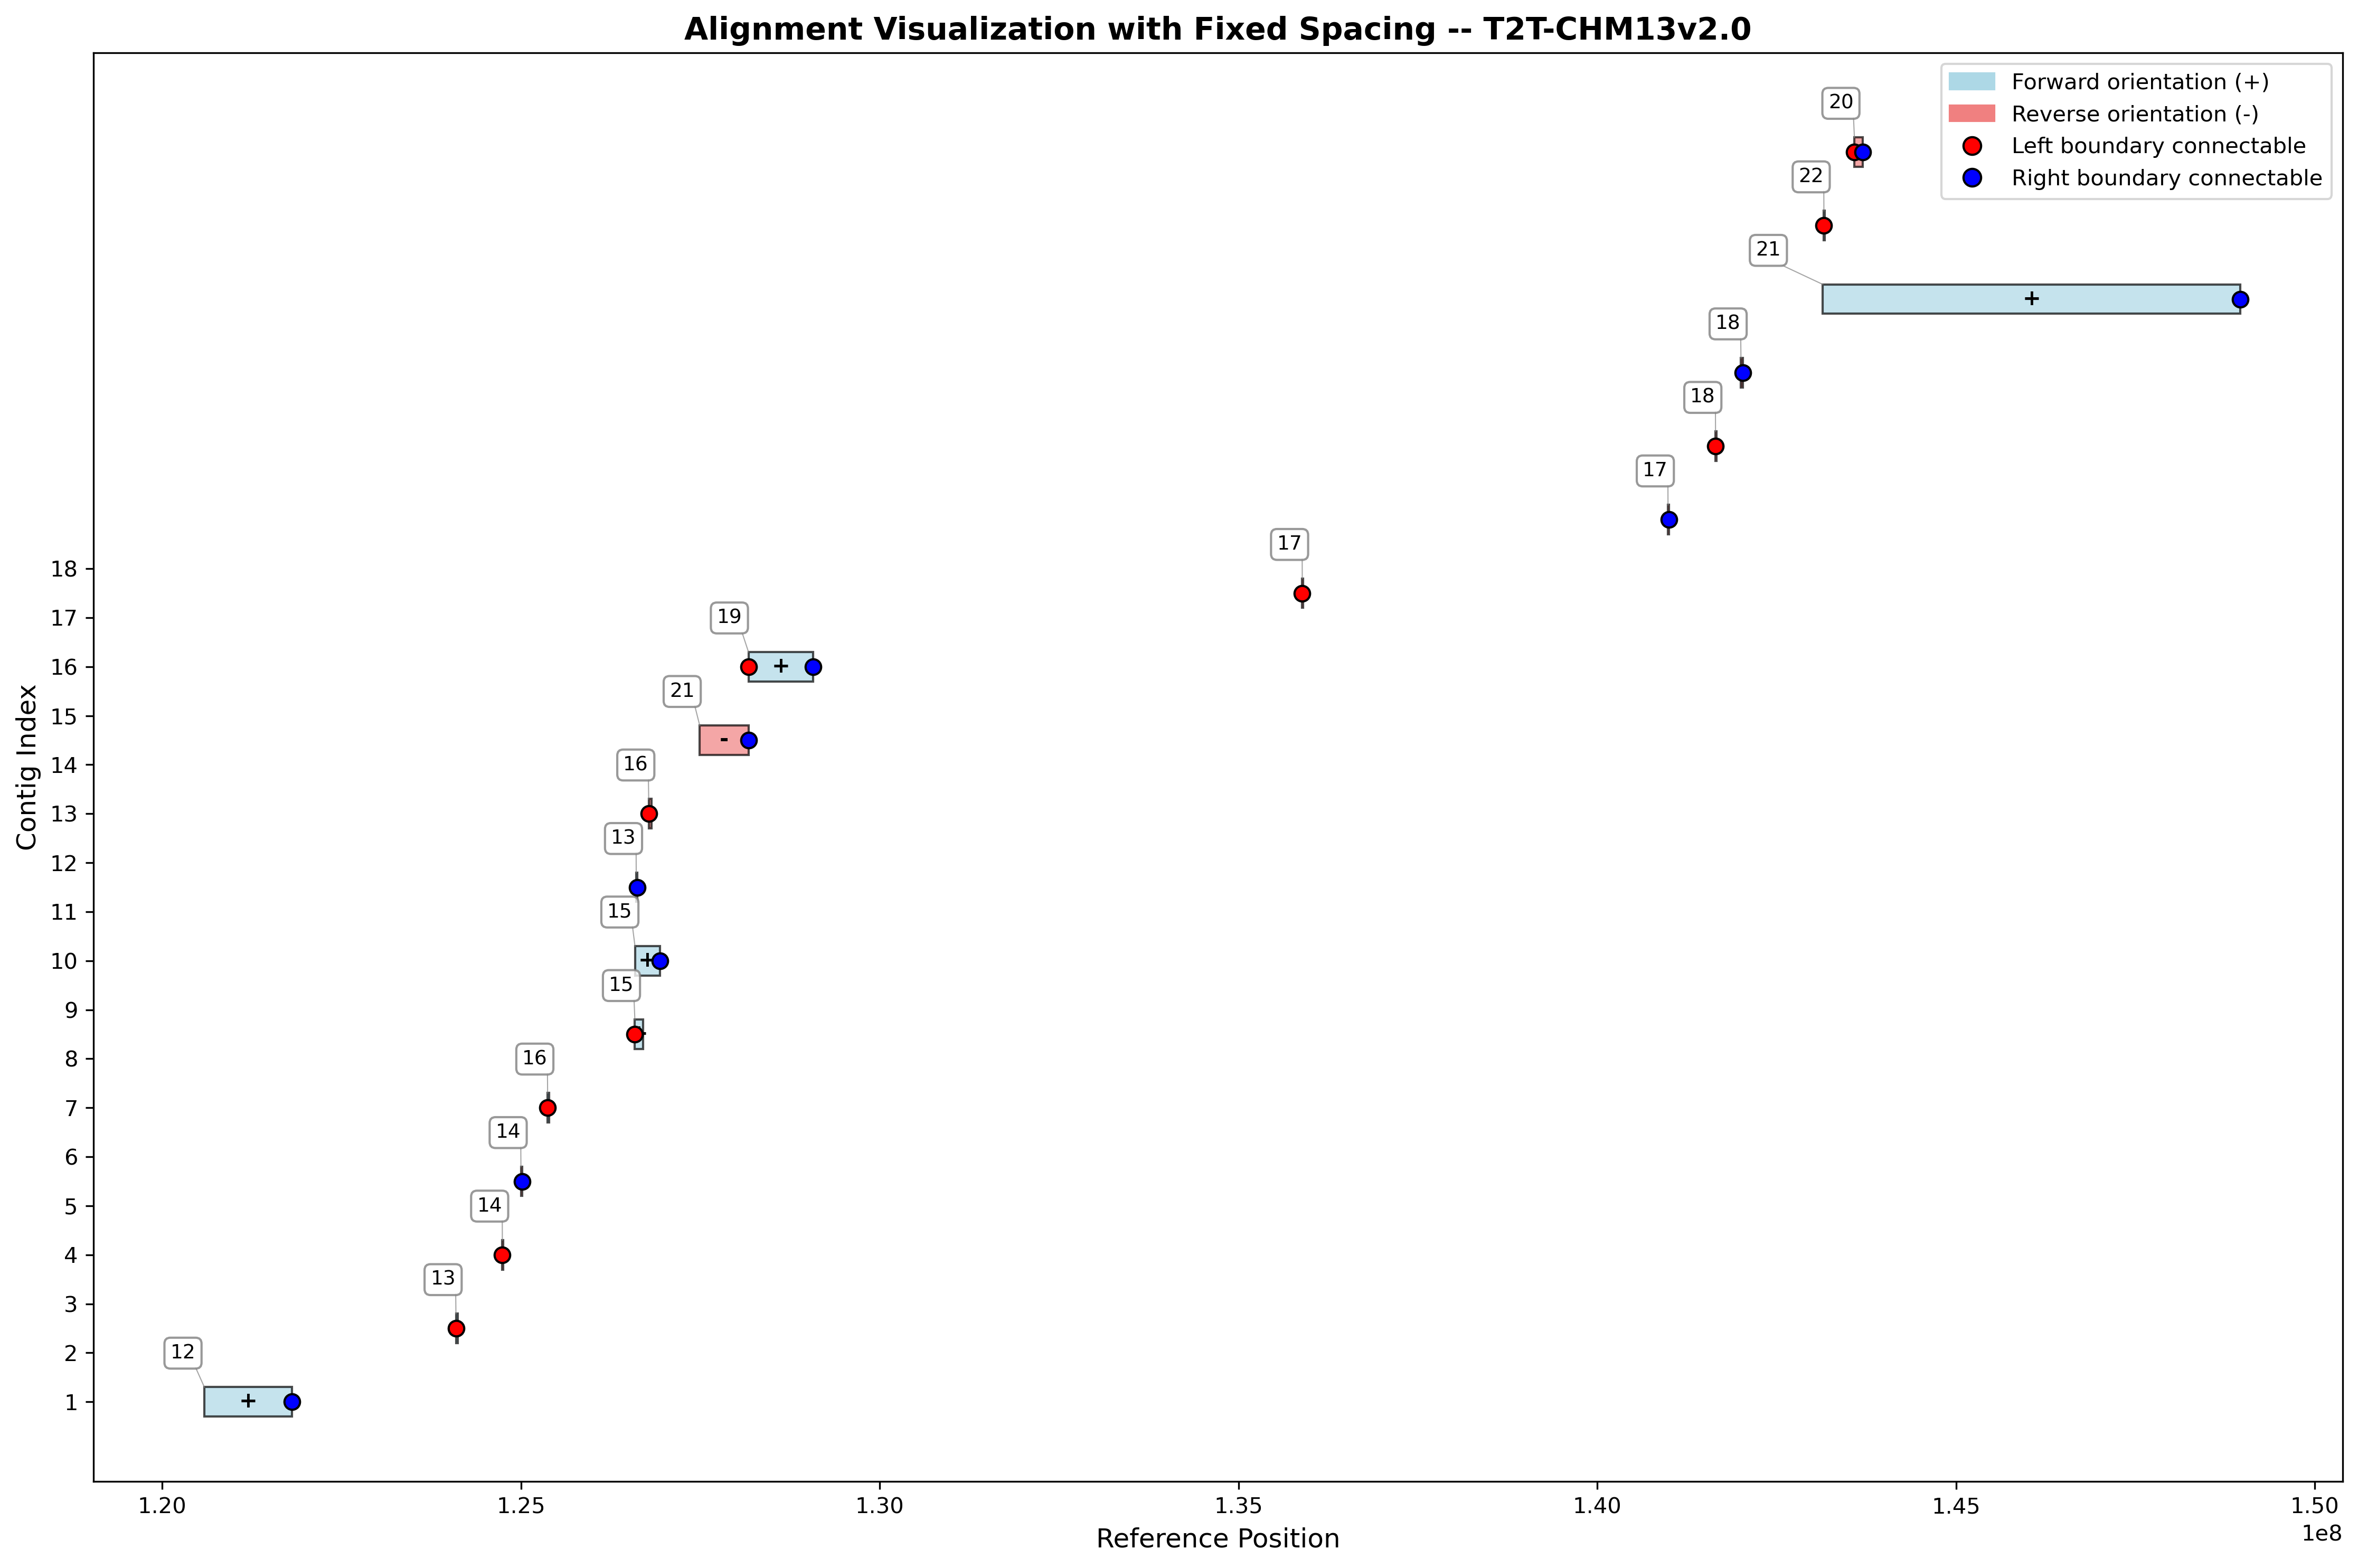

In [36]:
print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, spacing_type='fixed', spacing=1.5, Title="T2T-CHM13v2.0")

Loaded 14 alignment records
Reference range: 67673906 - 231570834

Parsed contig names:
h1tg000041l_chr1_RagTag_12 -> 12
h1tg000053l_chr1_RagTag_13 -> 13
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000055l_chr1_RagTag_16 -> 16
Fixed spacing visualization (uniform vertical distance):


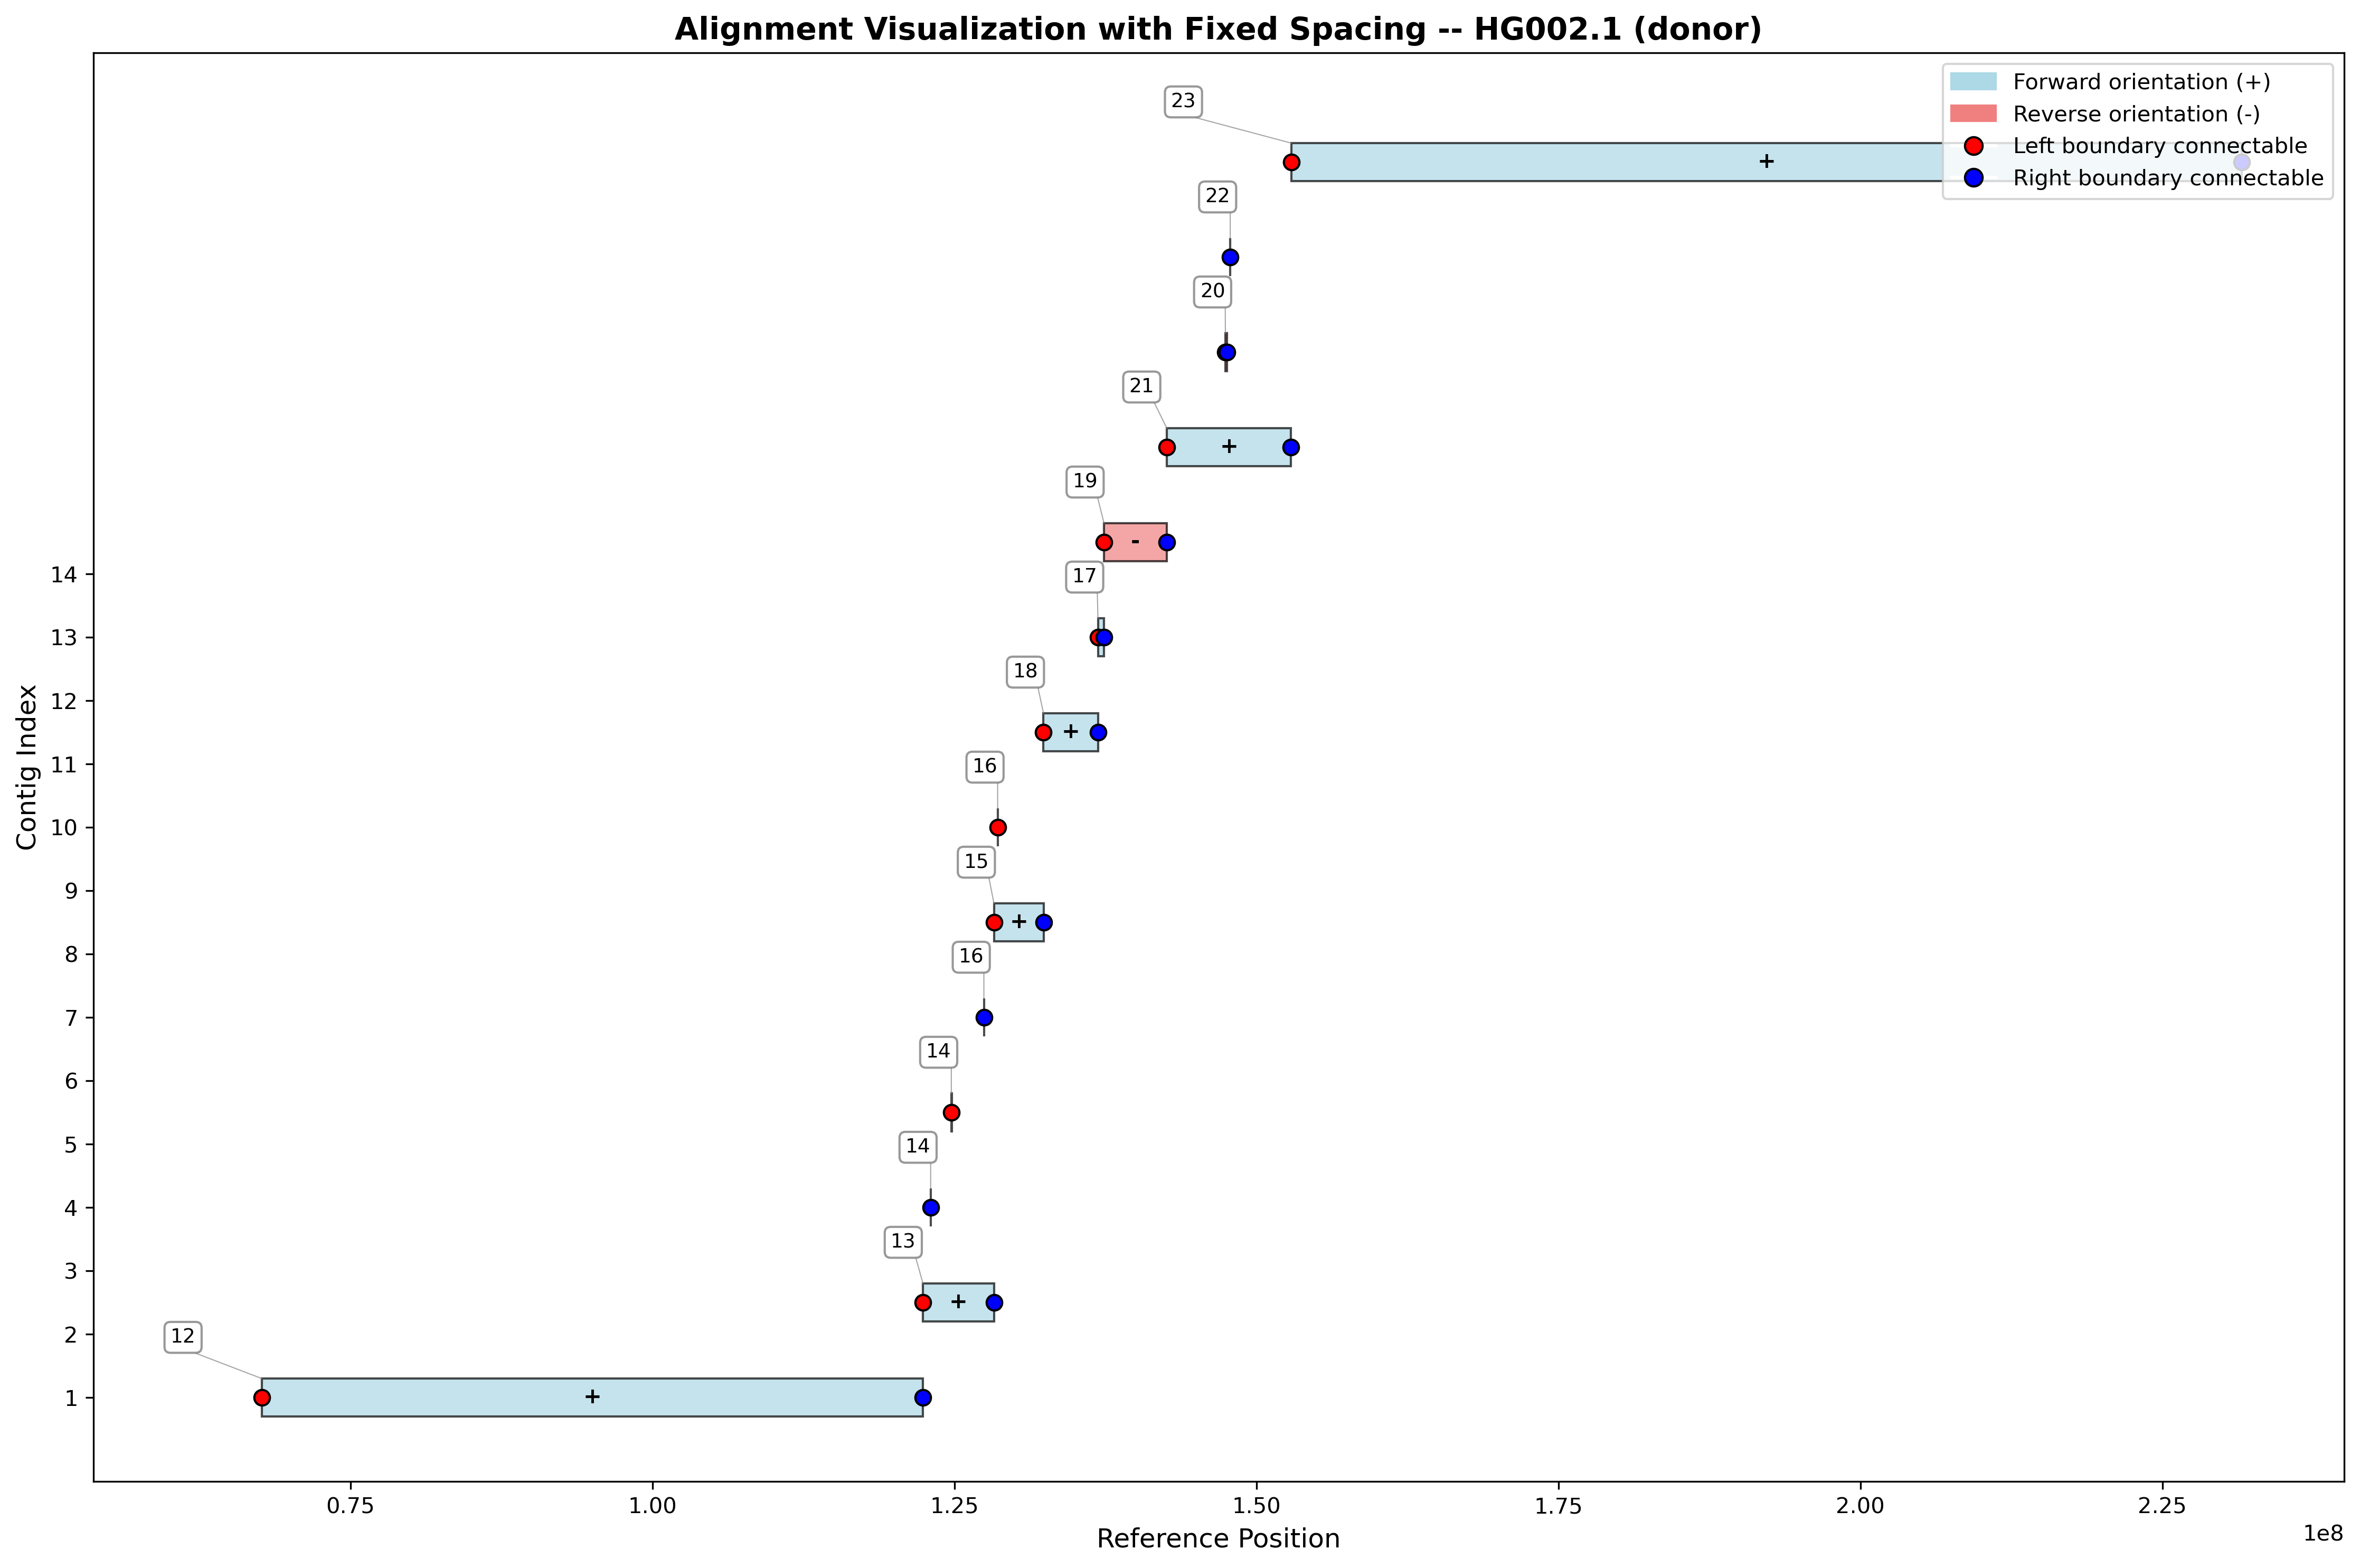

In [37]:
data_text = """14 h1tg000041l_chr1_RagTag_12 True True 24 54739147 	|	 + 67673906 122412394
20 h1tg000053l_chr1_RagTag_13 True True 154 5880496 	|	 + 122403222 128283564
31 h1tg000056l_chr1_RagTag_14 False True 651920 662490 	|	 + 123039632 123050203
43 h1tg000056l_chr1_RagTag_14 True False 27175 61779 	|	 + 124748852 124783442
78 h1tg000055l_chr1_RagTag_16 False True 22753 33395 	|	 - 127444037 127454668
81 h1tg000100l_chr1_RagTag_15 True True 42 4117523 	|	 + 128276256 132393728
90 h1tg000055l_chr1_RagTag_16 True False 2482984 2507777 	|	 - 128584082 128608782
102 h1tg000104l_chr1_RagTag_18 True True 6665 4523470 	|	 + 132379333 136896123
103 h1tg000103l_chr1_RagTag_17 True True 47 519639 	|	 + 136884605 137404194
104 h1tg000026l_chr1_RagTag_19 True True 64 5203984 	|	 - 137386970 142590884
105 h1tg000051l_chr1_RagTag_21 True True 7 10278065 	|	 + 142584493 152862997
106 h1tg000107l_chr1_RagTag_20 True True 7 119249 	|	 - 147433465 147552702
107 h1tg000395l_chr1_RagTag_22 False True 2479085 2490281 	|	 - 147835647 147847031
108 h1tg000110l_chr1_RagTag_23 True True 10 78538463 	|	 + 152878224 231570834
"""

# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, figsize=(15, 10), spacing_type='fixed', spacing=1.5, Title="HG002.1 (donor)")

Loaded 17 alignment records
Reference range: 70220318 - 148710089

Parsed contig names:
h1tg000041l_chr1_RagTag_12 -> 12
h1tg000053l_chr1_RagTag_13 -> 13
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000055l_chr1_RagTag_16 -> 16
h1tg000056l_chr1_RagTag_14 -> 14
Fixed spacing visualization (uniform vertical distance):


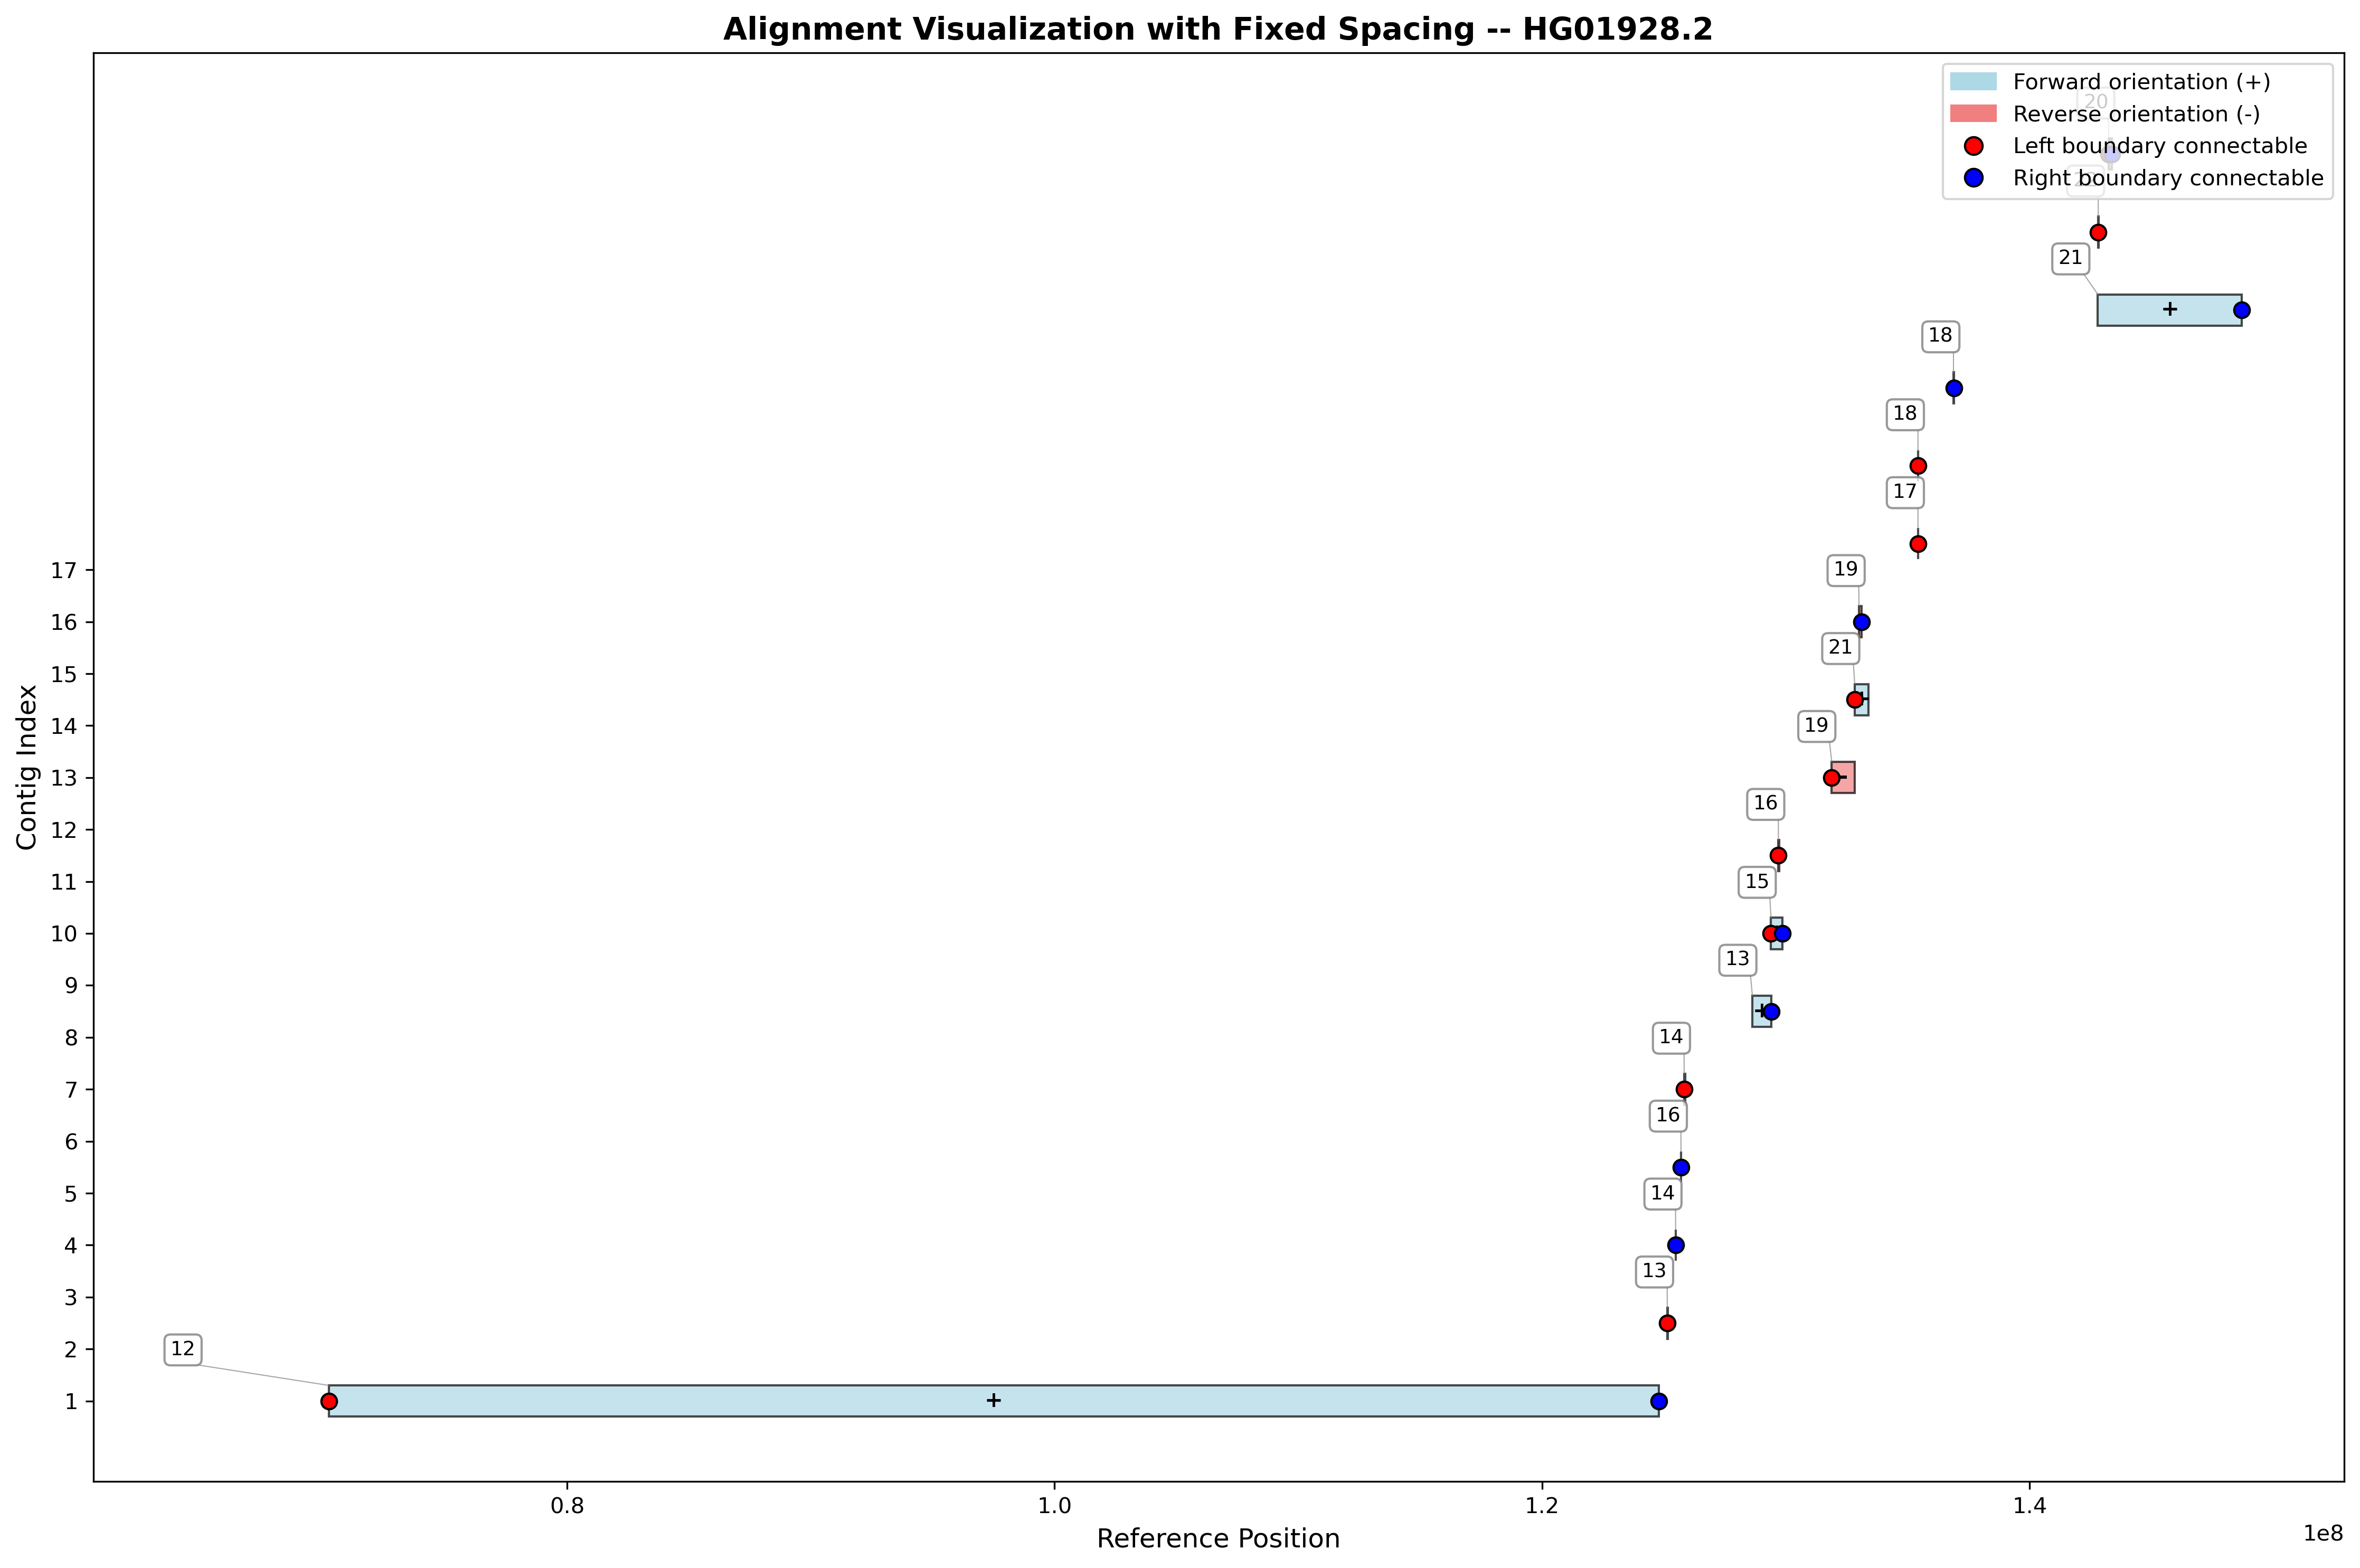

In [39]:
data_text = """27 h1tg000041l_chr1_RagTag_12 True True 24 54445236 	|	 + 70220318 124800037
34 h1tg000053l_chr1_RagTag_13 True False 5582 37348 	|	 + 125136693 125170405
46 h1tg000056l_chr1_RagTag_14 False True 595887 609164 	|	 + 125478739 125492020
56 h1tg000055l_chr1_RagTag_16 False True 11278 21440 	|	 - 125698738 125708883
60 h1tg000056l_chr1_RagTag_14 True False 57487 99905 	|	 + 125830188 125872569
133 h1tg000053l_chr1_RagTag_13 False True 5147418 5880496 	|	 + 128628881 129413201
138 h1tg000100l_chr1_RagTag_15 True True 105 481314 	|	 + 129392158 129867876
154 h1tg000055l_chr1_RagTag_16 True False 2482984 2508097 	|	 - 129697002 129721630
338 h1tg000026l_chr1_RagTag_19 True False 1258100 2100033 	|	 - 131884711 132833706
339 h1tg000051l_chr1_RagTag_21 True False 6839 545026 	|	 + 132827517 133381957
340 h1tg000026l_chr1_RagTag_19 False True 512361 626155 	|	 - 133003852 133118166
349 h1tg000103l_chr1_RagTag_17 True False 499972 512919 	|	 - 135423813 135436952
350 h1tg000104l_chr1_RagTag_18 True False 4504549 4517496 	|	 - 135423813 135436952
360 h1tg000104l_chr1_RagTag_18 False True 2200 15929 	|	 - 136880333 136894281
377 h1tg000051l_chr1_RagTag_21 False True 4408774 10278065 	|	 + 142801931 148710089
378 h1tg000395l_chr1_RagTag_22 True False 2479085 2490281 	|	 + 142818615 142829997
379 h1tg000107l_chr1_RagTag_20 True True 7 119249 	|	 - 143248628 143367891
"""

# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, figsize=(15, 10), spacing_type='fixed', spacing=1.5, Title="HG01928.2")

Loaded 18 alignment records
Reference range: 120270501 - 131475307

Parsed contig names:
h1tg000041l_chr1_RagTag_12 -> 12
h1tg000055l_chr1_RagTag_16 -> 16
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000100l_chr1_RagTag_15 -> 15
Fixed spacing visualization (uniform vertical distance):


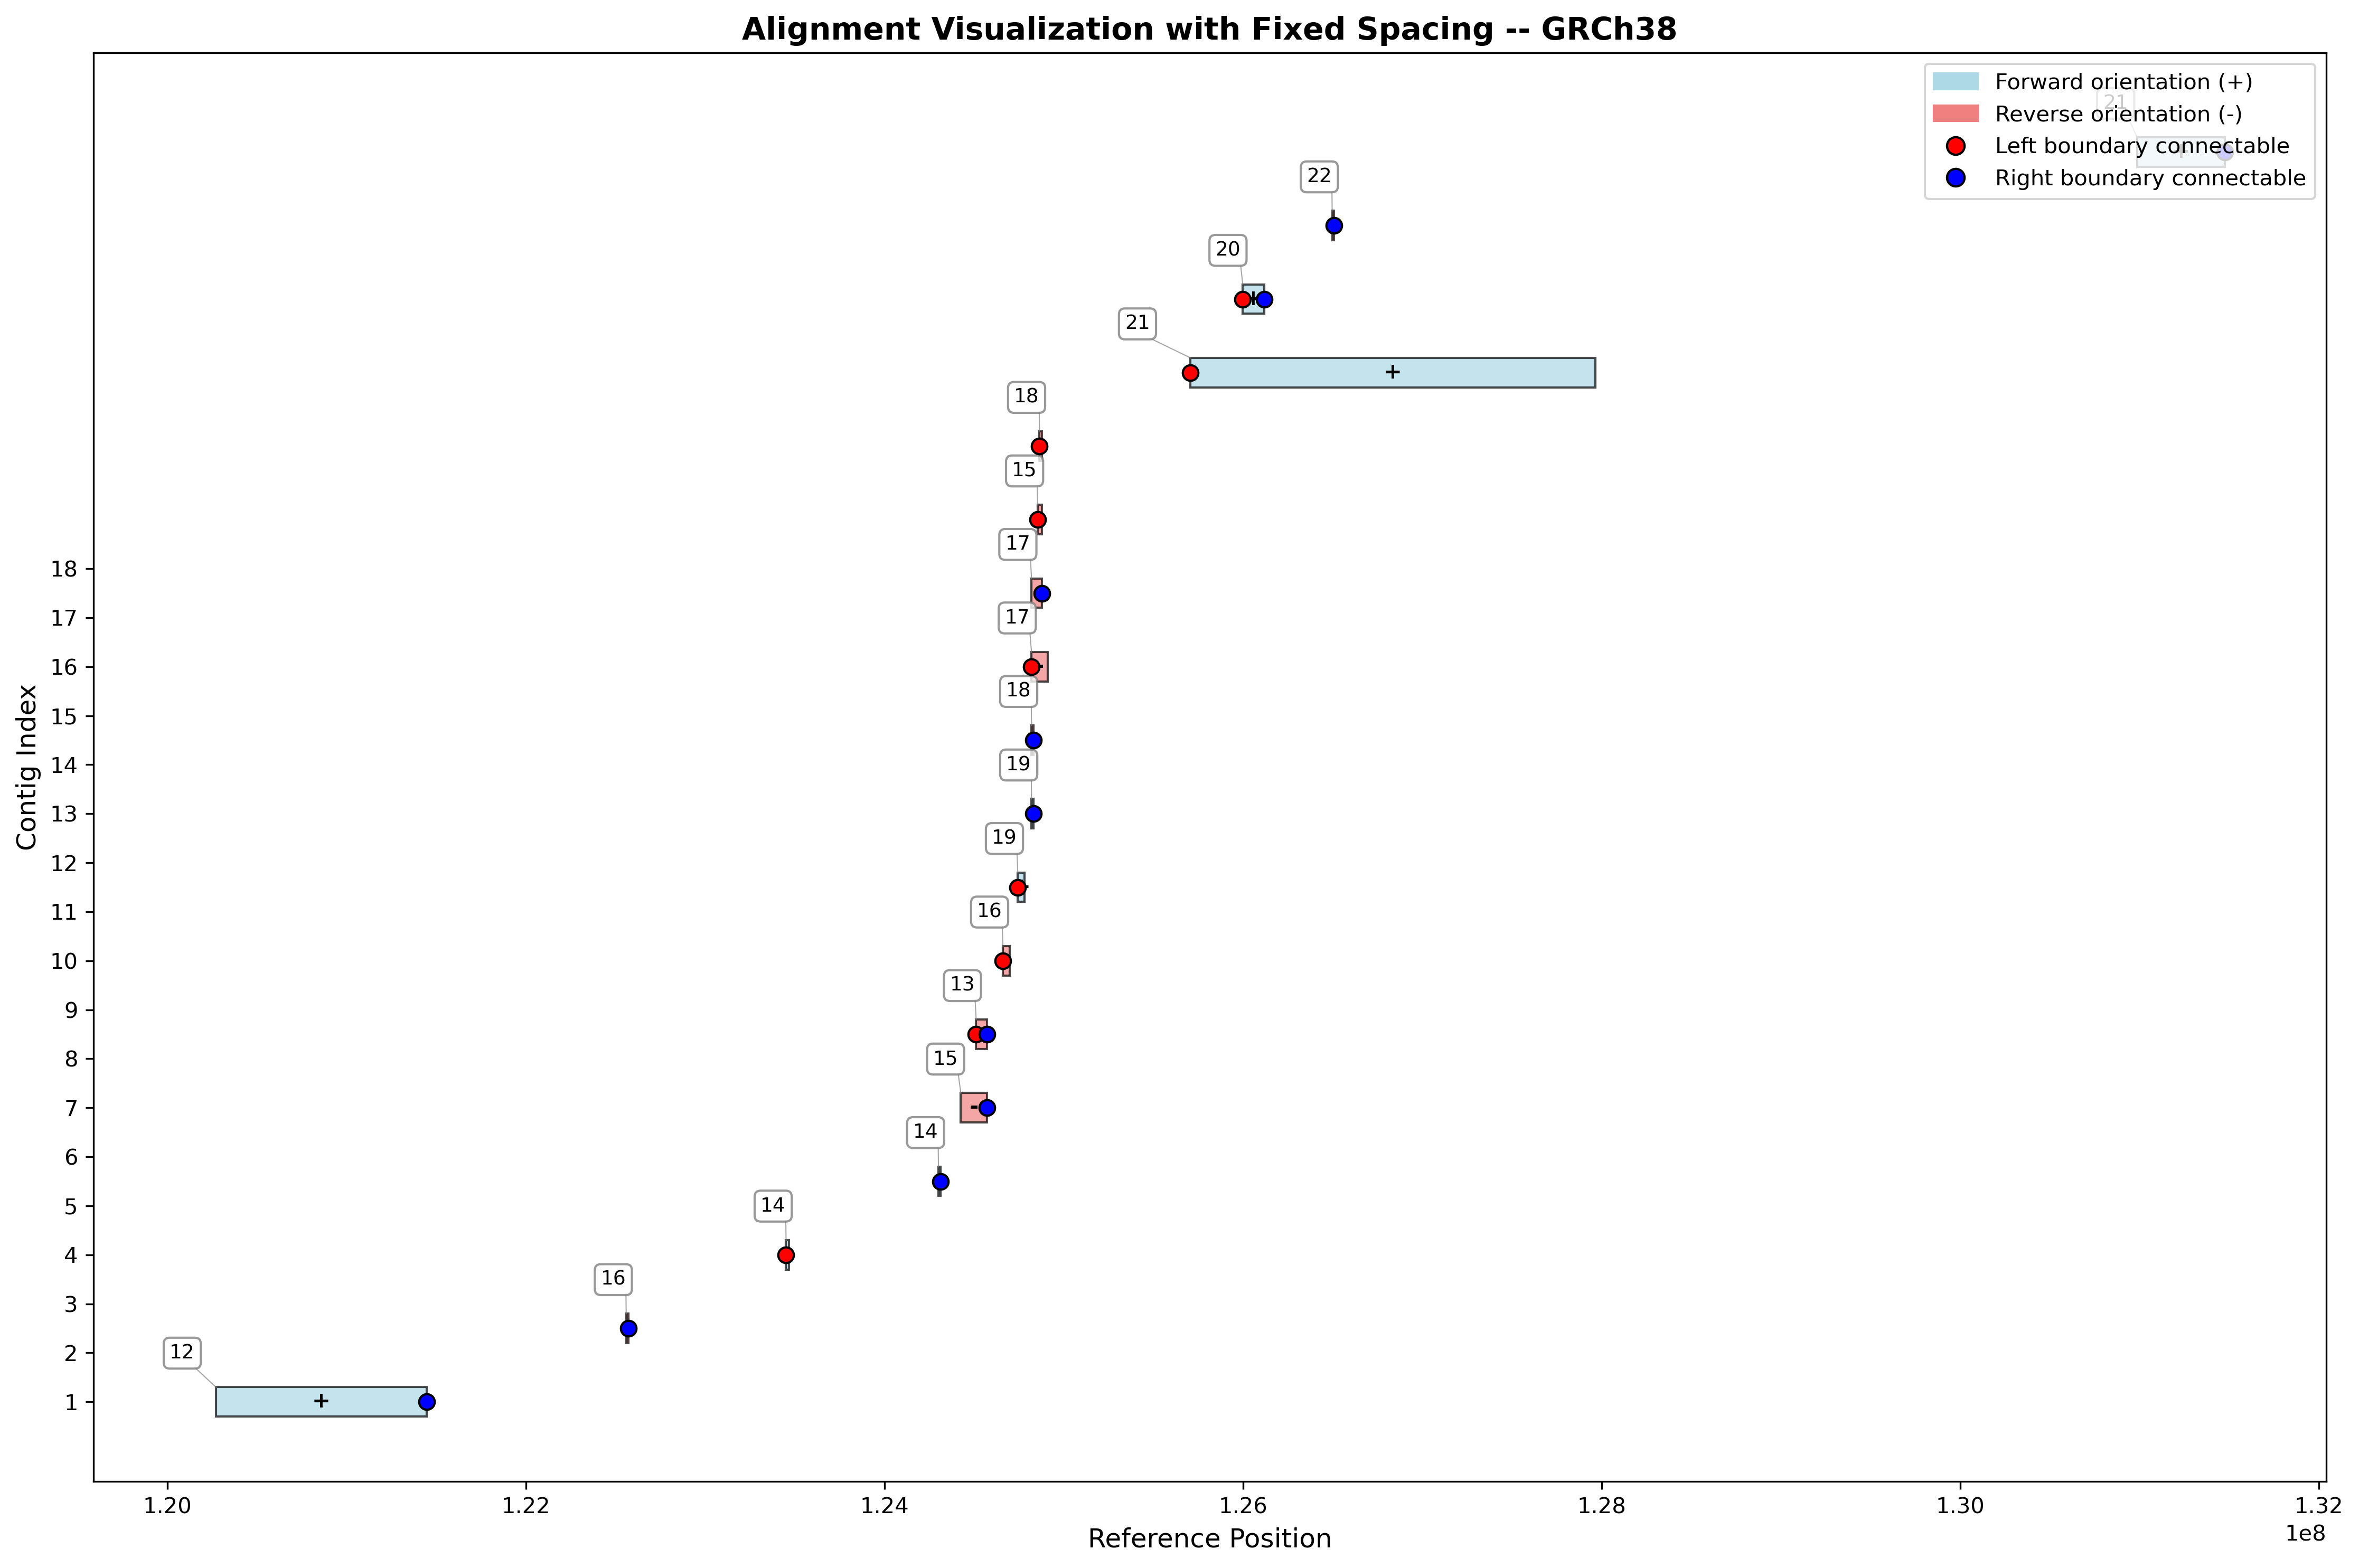

In [5]:
"""16 h1tg000041l_chr1_RagTag_12 True False 24 52902055 	|	 + 67140973 120017954"""
data_text = """17 h1tg000041l_chr1_RagTag_12 False True 53147410 54434733 	|	 + 120270501 121446215
29 h1tg000055l_chr1_RagTag_16 False True 561 13111 	|	 - 122558541 122571148
39 h1tg000056l_chr1_RagTag_14 True False 168749 183667 	|	 + 123450266 123465174
52 h1tg000056l_chr1_RagTag_14 False True 580373 592255 	|	 + 124300187 124312416
55 h1tg000100l_chr1_RagTag_15 False True 219 146421 	|	 - 124424917 124571264
57 h1tg000053l_chr1_RagTag_13 True True 5820866 5880496 	|	 - 124510566 124569798
62 h1tg000055l_chr1_RagTag_16 True False 2466633 2505561 	|	 - 124659751 124698666
80 h1tg000026l_chr1_RagTag_19 True False 1838494 1878249 	|	 + 124742593 124781411
83 h1tg000026l_chr1_RagTag_19 False True 5193040 5204000 	|	 + 124819208 124829382
84 h1tg000104l_chr1_RagTag_18 False True 9 12758 	|	 - 124819208 124831240
99 h1tg000103l_chr1_RagTag_17 True False 432108 518686 	|	 - 124819208 124910518
161 h1tg000103l_chr1_RagTag_17 False True 62 65209 	|	 - 124819244 124877274
218 h1tg000100l_chr1_RagTag_15 True False 4100574 4117505 	|	 - 124853417 124877336
219 h1tg000104l_chr1_RagTag_18 True False 4511967 4523656 	|	 - 124863546 124877274
222 h1tg000051l_chr1_RagTag_21 True False 4408774 6736039 	|	 + 125706329 127963228
223 h1tg000107l_chr1_RagTag_20 True True 7 119249 	|	 + 125997439 126116693
225 h1tg000395l_chr1_RagTag_22 False True 2479085 2490281 	|	 - 126496112 126507493
229 h1tg000051l_chr1_RagTag_21 False True 9783347 10278065 	|	 + 130985409 131475307
"""

"""230 h1tg000110l_chr1_RagTag_23 True True 10 78538463 	|	 + 131490558 210162871
"""


# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, figsize=(15, 10), spacing_type='fixed', spacing=1.5, Title="GRCh38")

Loaded 17 alignment records
Reference range: 122472185 - 141145455

Parsed contig names:
h1tg000055l_chr1_RagTag_16 -> 16
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000056l_chr1_RagTag_14 -> 14
h1tg000053l_chr1_RagTag_13 -> 13
h1tg000053l_chr1_RagTag_13 -> 13
Fixed spacing visualization (uniform vertical distance):


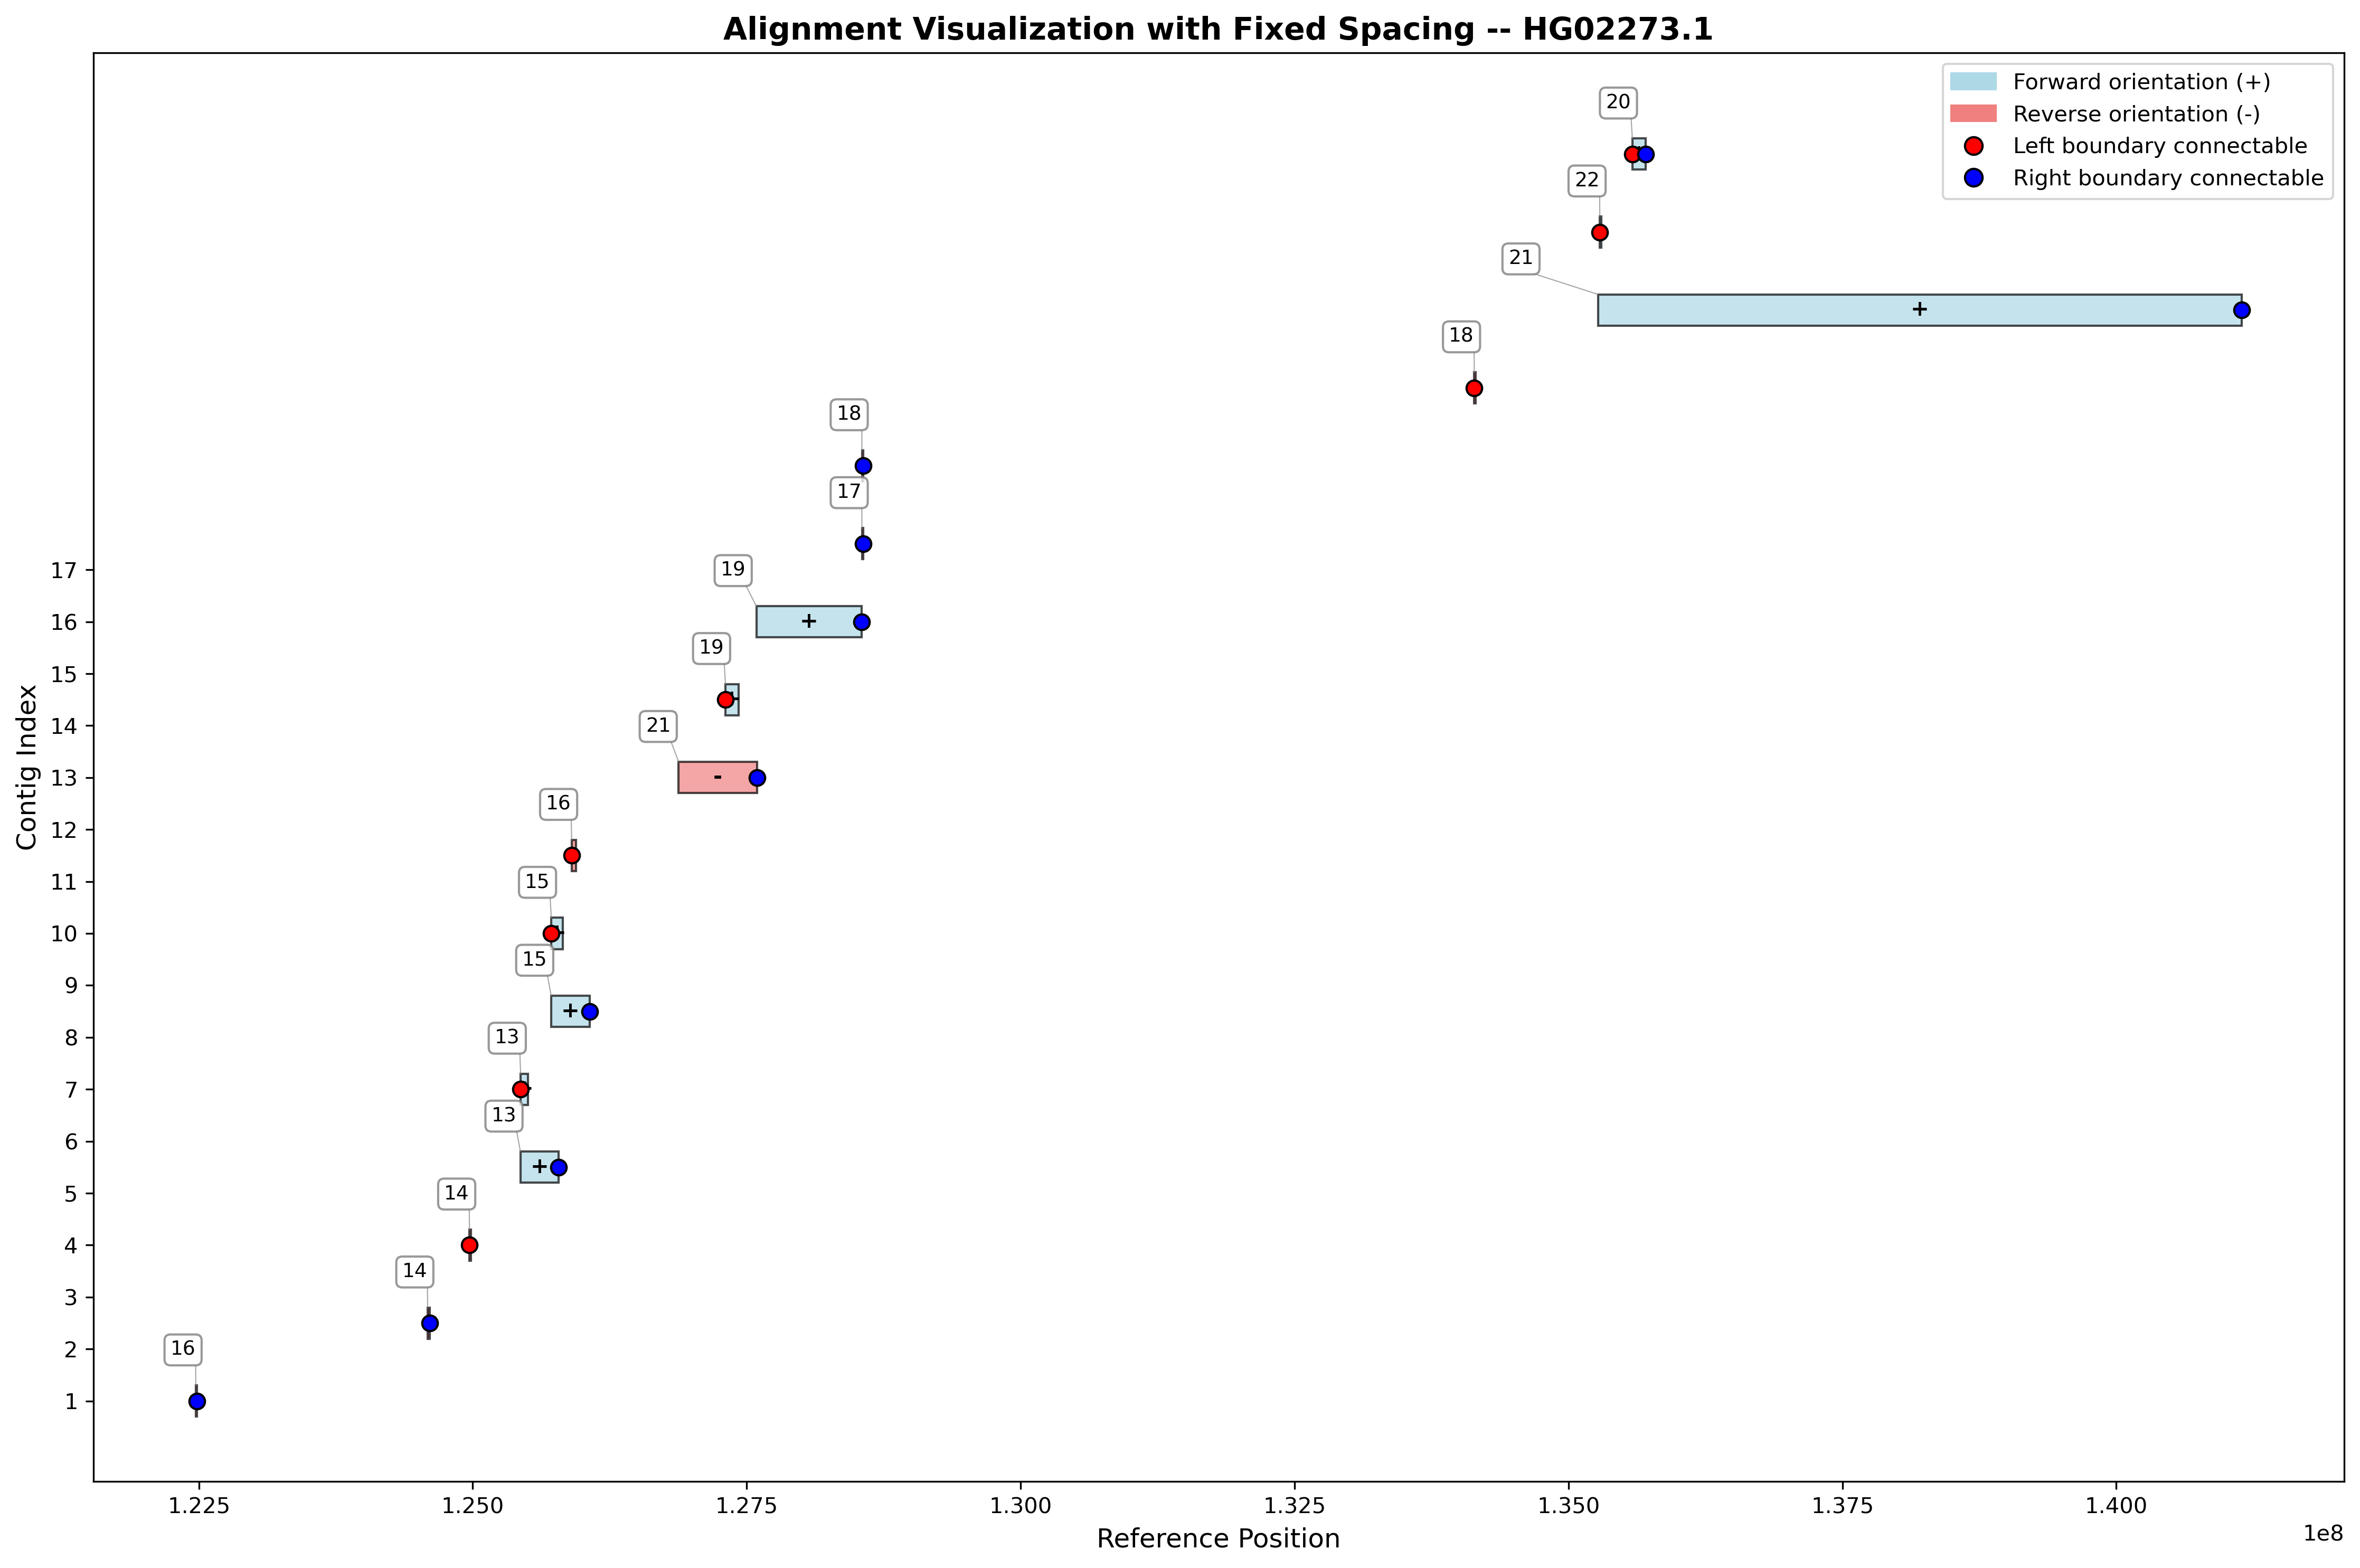

In [13]:
"""15 h1tg000041l_chr1_RagTag_12 True True 24 54436693 	|	 + 67620030 122116840"""
data_text = """37 h1tg000055l_chr1_RagTag_16 False True 5085 15556 	|	 - 122472185 122482651
57 h1tg000056l_chr1_RagTag_14 False True 20658 39441 	|	 - 124588284 124607060
62 h1tg000056l_chr1_RagTag_14 True False 637020 649930 	|	 - 124969776 124982689
68 h1tg000053l_chr1_RagTag_13 False True 5447147 5880496 	|	 + 125434812 125783085
69 h1tg000053l_chr1_RagTag_13 True False 5415397 5481821 	|	 + 125436644 125503068
70 h1tg000100l_chr1_RagTag_15 False True 51320 481778 	|	 + 125715793 126068131
71 h1tg000100l_chr1_RagTag_15 True False 105 109437 	|	 + 125716653 125822373
75 h1tg000055l_chr1_RagTag_16 True False 2464418 2506210 	|	 - 125902525 125942361
111 h1tg000051l_chr1_RagTag_21 False True 6839 584396 	|	 - 126879318 127594035
112 h1tg000026l_chr1_RagTag_19 True False 512361 630164 	|	 + 127306442 127424129
113 h1tg000026l_chr1_RagTag_19 False True 1258100 2104684 	|	 + 127587846 128547709
116 h1tg000103l_chr1_RagTag_17 False True 140072 150618 	|	 - 128551725 128562386
118 h1tg000104l_chr1_RagTag_18 False True 192428 202974 	|	 - 128551725 128562386
130 h1tg000104l_chr1_RagTag_18 True False 4397962 4412427 	|	 - 134140291 134154795
137 h1tg000051l_chr1_RagTag_21 False True 4408774 10278065 	|	 + 135269301 141145455
138 h1tg000395l_chr1_RagTag_22 True False 2479085 2490281 	|	 + 135285942 135297322
139 h1tg000107l_chr1_RagTag_20 True True 7 119249 	|	 + 135582998 135702255
"""
"""140 h1tg000110l_chr1_RagTag_23 True True 10 78538463 	|	 + 141160694 220073729
"""

data_text_full = """0 h1tg000017l_chr1_RagTag_0 True True 11 729835 	|	 + 70674 801343
1 h1tg000018l_chr1_RagTag_1 True True 3 875152 	|	 + 903132 1780118
2 h1tg000020l_chr1_RagTag_2 True True 12 148645 	|	 + 1783975 1932729
3 h1tg000021l_chr1_RagTag_3 True True 7 2214352 	|	 + 2332547 4528568
4 h1tg000022l_chr1_RagTag_4 True True 10 1491953 	|	 + 4539782 6030684
5 h1tg000027l_chr1_RagTag_5 True True 14 116607 	|	 + 6057426 6174020
6 h1tg000028l_chr1_RagTag_6 True True 16 298119 	|	 + 6179833 6477888
7 h1tg000029l_chr1_RagTag_10 True False 6 10538836 	|	 + 6480621 16998283
8 h1tg000395l_chr1_RagTag_22 True False 2728115 2740732 	|	 - 8356600 8369266
9 h1tg000030l_chr1_RagTag_7 True True 2 69458 	|	 + 12556622 12626088
10 h1tg000032l_chr1_RagTag_8 False True 0 116623 	|	 - 12887139 13005460
11 h1tg000032l_chr1_RagTag_8 True False 64839 160782 	|	 - 12958106 13084408
12 h1tg000033l_chr1_RagTag_9 True True 70 28651 	|	 - 16103985 16132539
13 h1tg000034l_chr1_RagTag_11 True True 5 55177 	|	 + 16624583 16679773
14 h1tg000029l_chr1_RagTag_10 False True 10436140 61279732 	|	 + 16629941 67612182
15 h1tg000041l_chr1_RagTag_12 True True 24 54436693 	|	 + 67620030 122116840
37 h1tg000055l_chr1_RagTag_16 False True 5085 15556 	|	 - 122472185 122482651
57 h1tg000056l_chr1_RagTag_14 False True 20658 39441 	|	 - 124588284 124607060
62 h1tg000056l_chr1_RagTag_14 True False 637020 649930 	|	 - 124969776 124982689
68 h1tg000053l_chr1_RagTag_13 False True 5447147 5880496 	|	 + 125434812 125783085
69 h1tg000053l_chr1_RagTag_13 True False 5415397 5481821 	|	 + 125436644 125503068
70 h1tg000100l_chr1_RagTag_15 False True 51320 481778 	|	 + 125715793 126068131
71 h1tg000100l_chr1_RagTag_15 True False 105 109437 	|	 + 125716653 125822373
75 h1tg000055l_chr1_RagTag_16 True False 2464418 2506210 	|	 - 125902525 125942361
111 h1tg000051l_chr1_RagTag_21 False True 6839 584396 	|	 - 126879318 127594035
112 h1tg000026l_chr1_RagTag_19 True False 512361 630164 	|	 + 127306442 127424129
113 h1tg000026l_chr1_RagTag_19 False True 1258100 2104684 	|	 + 127587846 128547709
116 h1tg000103l_chr1_RagTag_17 False True 140072 150618 	|	 - 128551725 128562386
118 h1tg000104l_chr1_RagTag_18 False True 192428 202974 	|	 - 128551725 128562386
130 h1tg000104l_chr1_RagTag_18 True False 4397962 4412427 	|	 - 134140291 134154795
137 h1tg000051l_chr1_RagTag_21 False True 4408774 10278065 	|	 + 135269301 141145455
138 h1tg000395l_chr1_RagTag_22 True False 2479085 2490281 	|	 + 135285942 135297322
139 h1tg000107l_chr1_RagTag_20 True True 7 119249 	|	 + 135582998 135702255
140 h1tg000110l_chr1_RagTag_23 True True 10 78538463 	|	 + 141160694 220073729
142 h1tg000126l_chr1_RagTag_24 True True 17 110790 	|	 + 217724063 217834836
143 h1tg000127l_chr1_RagTag_25 True True 7 446588 	|	 + 220102784 220548553
144 h1tg000128l_chr1_RagTag_26 True True 14 1034636 	|	 + 220549297 221583957
145 h1tg000129l_chr1_RagTag_27 True True 18 1788627 	|	 + 221606861 223395007
146 h1tg000130l_chr1_RagTag_28 True False 11 15353438 	|	 + 223400471 238754519
160 h1tg000103l_chr1_RagTag_17 True False 501361 514125 	|	 - 249495488 249508300
161 h1tg000130l_chr1_RagTag_28 False True 15325766 15615975 	|	 + 251044959 251331509
162 h1tg000131l_chr1_RagTag_29 True True 1503 306545 	|	 + 251332176 251637402
163 h1tg000132l_chr1_RagTag_30 True True 12 474160 	|	 + 251683739 252157799
164 h1tg000133l_chr1_RagTag_31 True True 14 712774 	|	 + 252196657 252927376"""

# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, figsize=(15, 10), spacing_type='fixed', spacing=1.5, Title="HG02273.1")

Loaded 9 alignment records
Reference range: 88221076 - 94031721

Parsed contig names:
h1tg000141l_chr2_RagTag_4 -> 4
h1tg000142l_chr2_RagTag_5 -> 5
h1tg000145l_chr2_RagTag_8 -> 8
h1tg000139l_chr2_RagTag_6 -> 6
h1tg000140l_chr2_RagTag_7 -> 7
Fixed spacing visualization (uniform vertical distance):


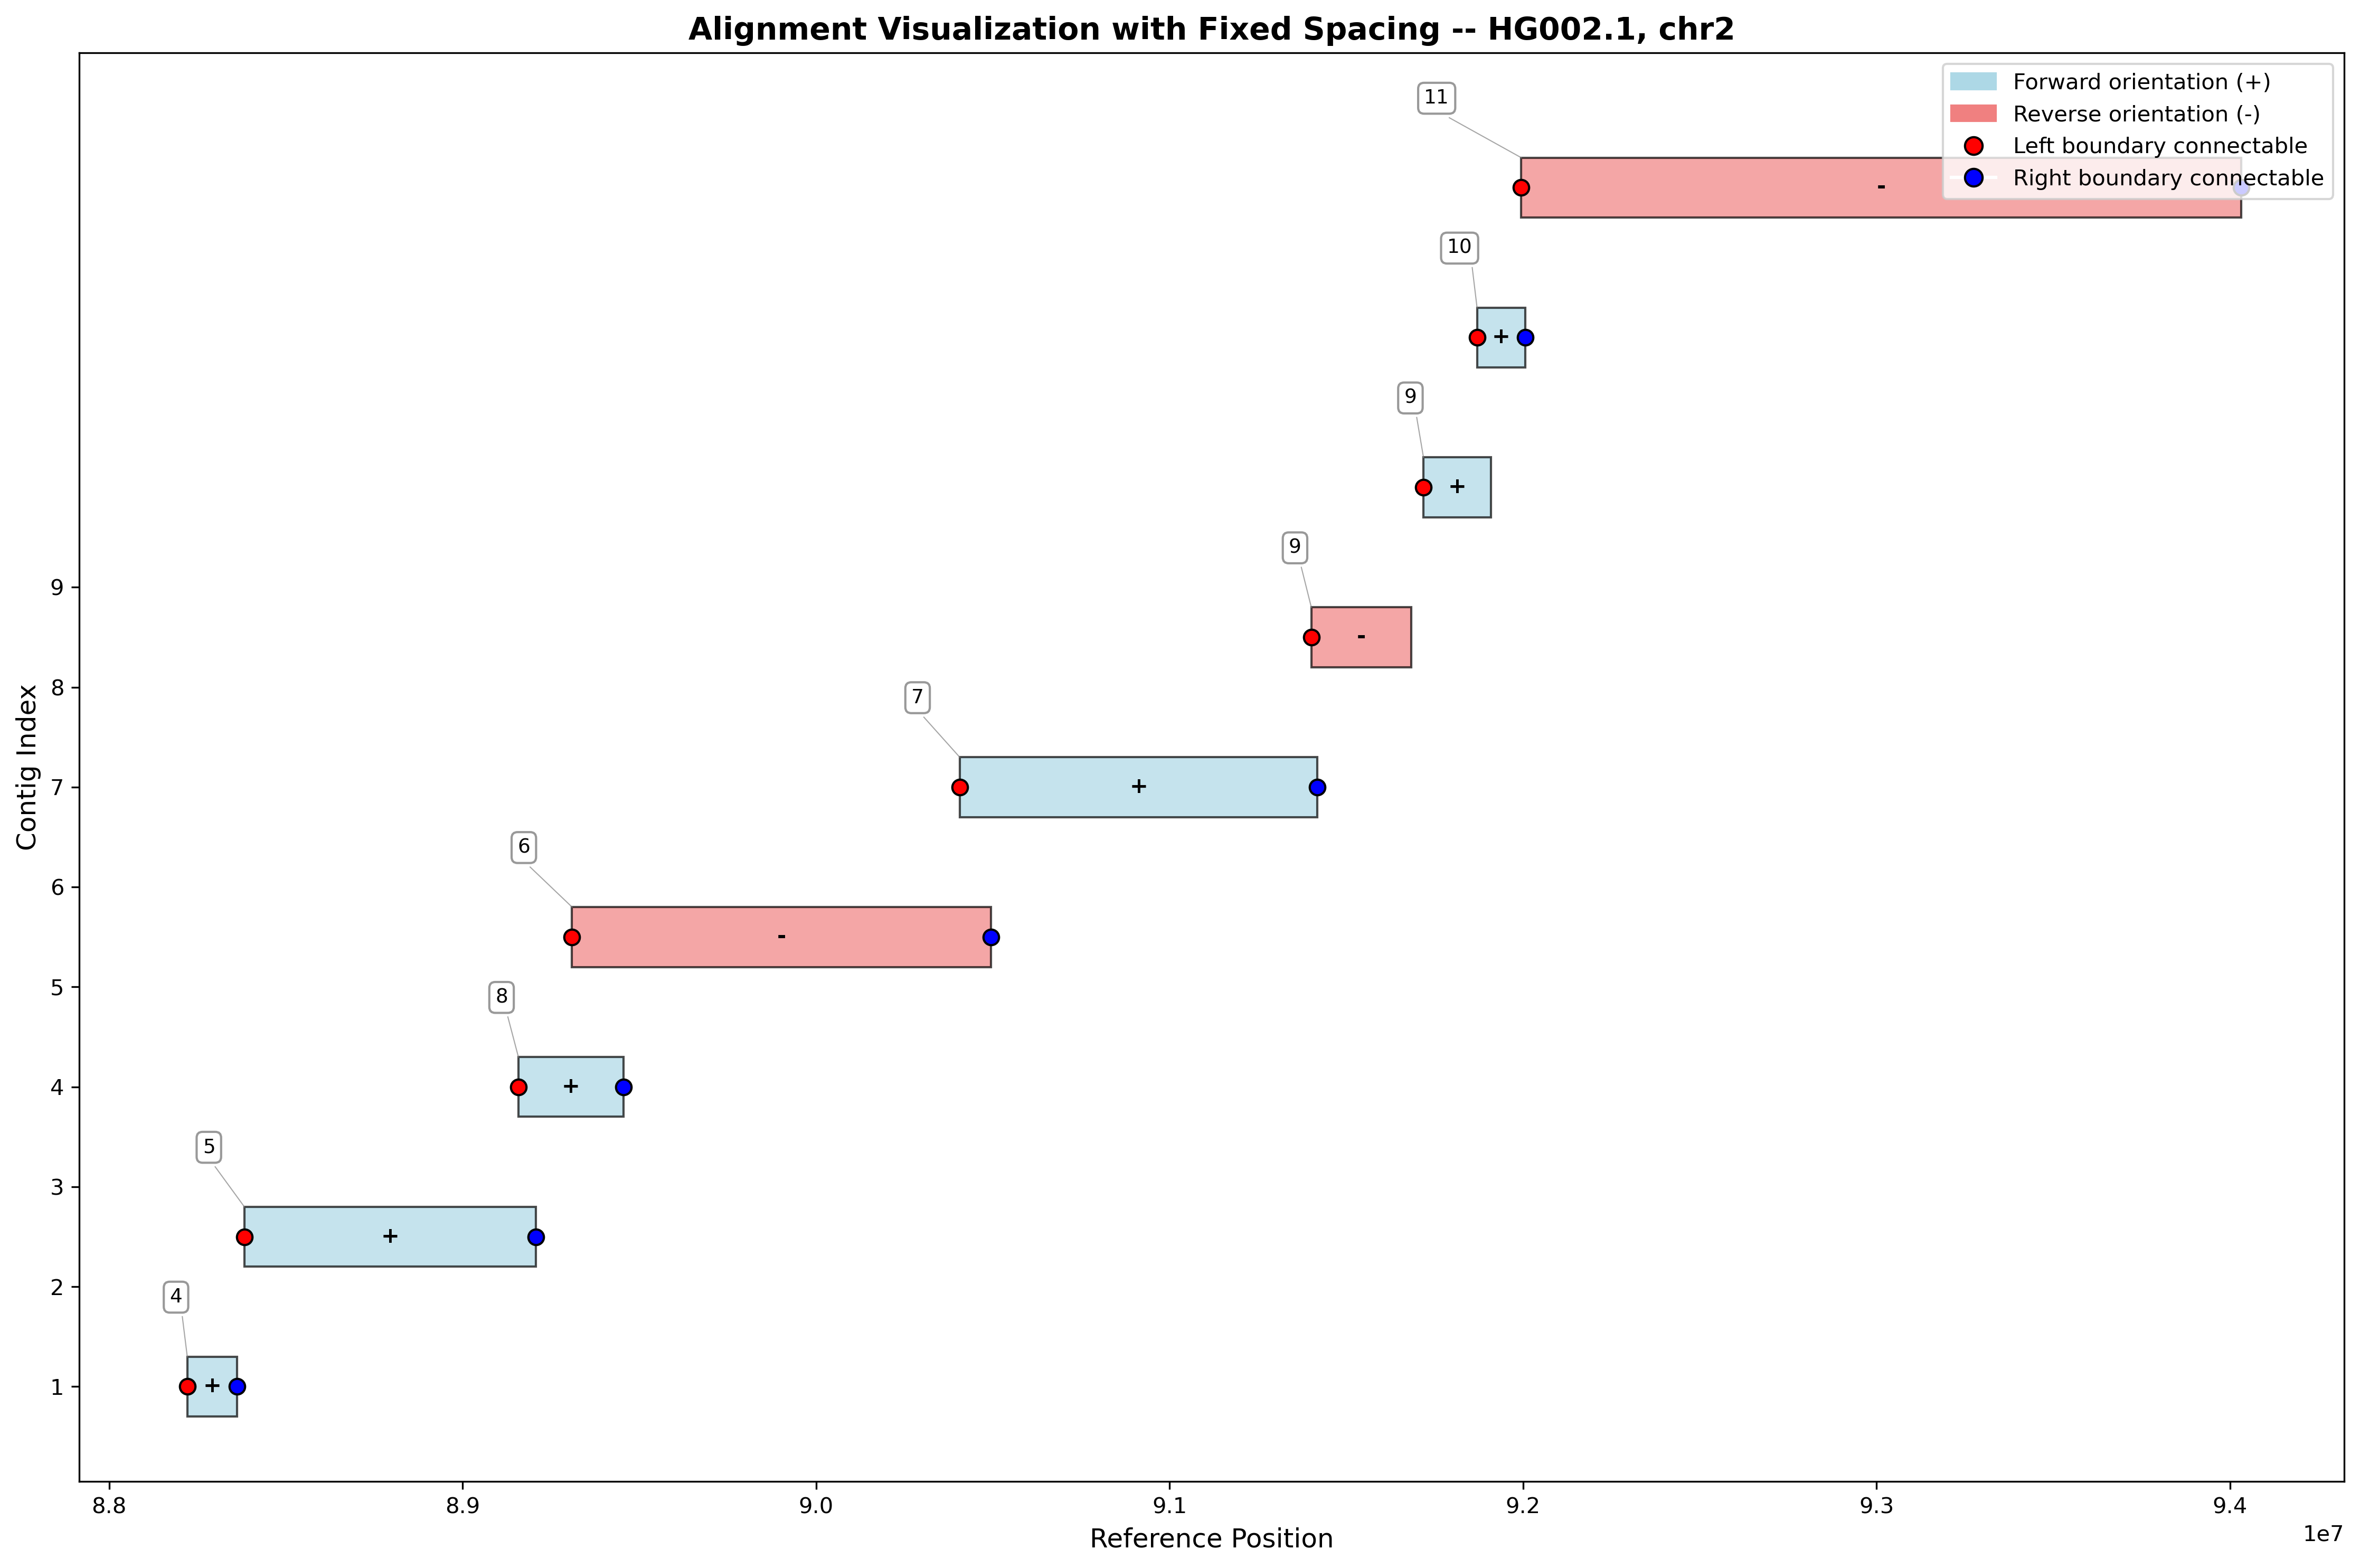

In [4]:
"""0 h1tg000134l_chr2_RagTag_0 True True 1611 200346 	|	 + 116 198640
1 h1tg000135l_chr2_RagTag_1 True True 16 59835547 	|	 + 205969 60041585
2 h1tg000136l_chr2_RagTag_2 True True 49 8408901 	|	 + 60080055 68488923
3 h1tg000137l_chr2_RagTag_3 True True 16 19730571 	|	 + 68489055 88219410
"""
data_text = """4 h1tg000141l_chr2_RagTag_4 True True 13 140268 	|	 + 88221076 88361336
5 h1tg000142l_chr2_RagTag_5 True True 8 824854 	|	 + 88382501 89207342
6 h1tg000145l_chr2_RagTag_8 True True 4 297520 	|	 + 89157772 89455261
7 h1tg000139l_chr2_RagTag_6 True True 18 1204360 	|	 - 89309534 90494215
8 h1tg000140l_chr2_RagTag_7 True True 18 1016622 	|	 + 90406229 91418576
9 h1tg000138l_chr2_RagTag_9 True False 138401 421016 	|	 - 91401027 91683613
10 h1tg000138l_chr2_RagTag_9 True False 17 191581 	|	 + 91718367 91909950
11 h1tg000155l_chr2_RagTag_10 True True 8 136559 	|	 + 91869887 92006448
12 h1tg000153l_chr2_RagTag_11 True True 9 2036682 	|	 - 91995062 94031721"""

"""
13 h1tg000152l_chr2_RagTag_12 True True 48 1825154 	|	 + 94003994 95829113
14 h1tg000164l_chr2_RagTag_13 True True 4 27489864 	|	 - 95831081 123320999
15 h1tg000166l_chr2_RagTag_14 True True 15 555532 	|	 + 123323164 123878686
16 h1tg000167l_chr2_RagTag_15 True True 7 785159 	|	 + 123931625 124716777"""

"""17 h1tg000168l_chr2_RagTag_16 True True 16 5419654 	|	 + 124779306 130198805
18 h1tg000169l_chr2_RagTag_17 True True 10 111664206 	|	 + 130203613 241867613"""

# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, figsize=(15, 10), spacing_type='fixed', spacing=1.5, Title="HG002.1, chr2")

Loaded 23 alignment records
Reference range: 11855208 - 77369287

Parsed contig names:
h1tg000049l_chr5_RagTag_4 -> 4
h1tg000092l_chr5_RagTag_6 -> 6
h1tg000093l_chr5_RagTag_7 -> 7
h1tg000079l_chr5_RagTag_19 -> 19
h1tg000073l_chr5_RagTag_15 -> 15
Fixed spacing visualization (uniform vertical distance):


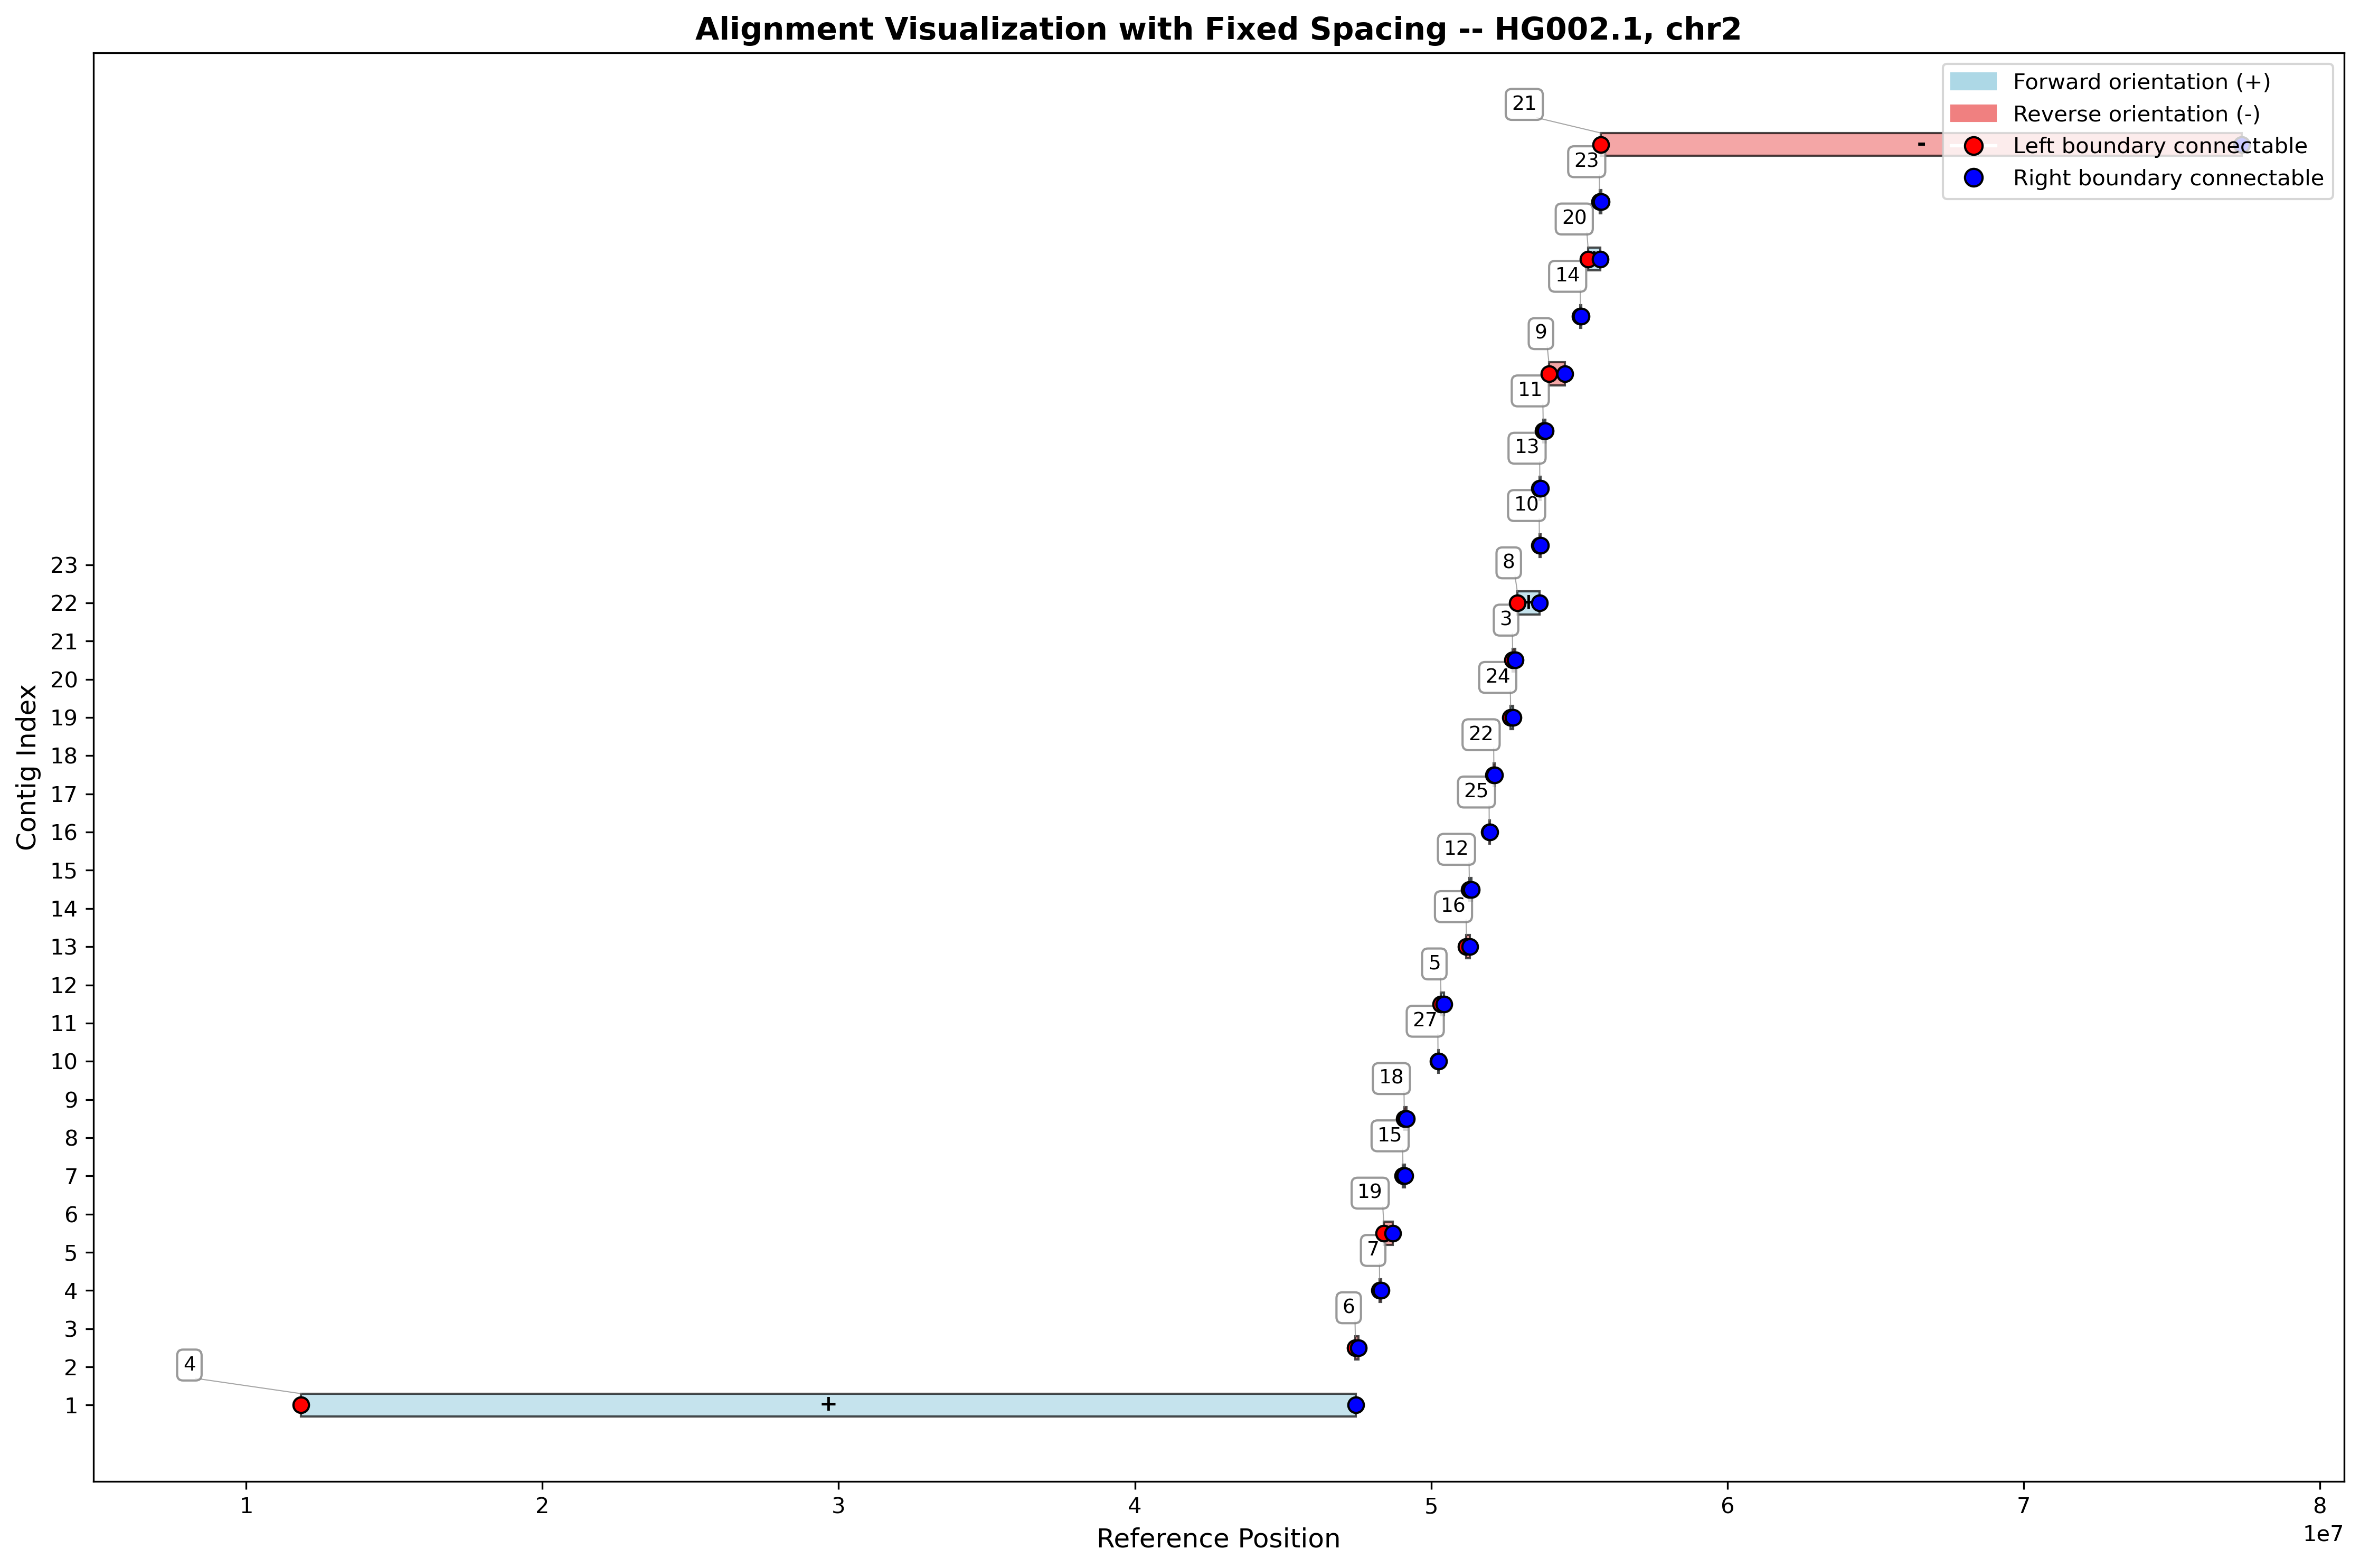

In [11]:
"""0 h1tg000220l_chr5_RagTag_0 True True 2973 922857 	|	 + 246 921902
1 h1tg000222l_chr5_RagTag_1 True True 10 2351107 	|	 + 944165 3295227
2 h1tg000223l_chr5_RagTag_2 True True 4 8553968 	|	 + 3297675 11851549
"""

data_text = """3 h1tg000049l_chr5_RagTag_4 True True 4 35583601 	|	 + 11855208 47455480
4 h1tg000092l_chr5_RagTag_6 True True 49 107895 	|	 - 47442737 47550583
5 h1tg000093l_chr5_RagTag_7 True True 94 44306 	|	 - 48261151 48305363
6 h1tg000079l_chr5_RagTag_19 True True 69 300931 	|	 - 48399220 48700082
7 h1tg000073l_chr5_RagTag_15 True True 211 59935 	|	 + 49048058 49107782
8 h1tg000072l_chr5_RagTag_18 True True 501 76671 	|	 - 49093331 49169501
9 h1tg000097l_chr5_RagTag_27 True True 92 32316 	|	 + 50232248 50264472
10 h1tg000063l_chr5_RagTag_5 True True 153 101983 	|	 + 50331779 50433608
11 h1tg000088l_chr5_RagTag_16 True True 141 109069 	|	 - 51192439 51301367
12 h1tg000098l_chr5_RagTag_12 True True 130 76118 	|	 + 51289783 51365771
13 h1tg000086l_chr5_RagTag_25 True True 70 29058 	|	 - 51961728 51990716
14 h1tg000070l_chr5_RagTag_22 True True 135 36857 	|	 - 52117634 52154356
15 h1tg000090l_chr5_RagTag_24 True True 147 83000 	|	 + 52683442 52766295
16 h1tg000089l_chr5_RagTag_3 True True 223 95284 	|	 - 52752730 52847791
17 h1tg000060l_chr5_RagTag_8 True True 45 762280 	|	 + 52909593 53665715
18 h1tg000061l_chr5_RagTag_10 True True 80 47581 	|	 - 53654643 53701465
19 h1tg000062l_chr5_RagTag_13 True True 36 35014 	|	 + 53669324 53704302
20 h1tg000095l_chr5_RagTag_11 True True 30 80661 	|	 + 53782212 53862843
21 h1tg000067l_chr5_RagTag_9 True True 128 523878 	|	 - 53975723 54513741
22 h1tg000077l_chr5_RagTag_14 True True 143 30924 	|	 + 55038784 55069565
23 h1tg000069l_chr5_RagTag_20 True True 52 410363 	|	 + 55299274 55704493
24 h1tg000096l_chr5_RagTag_23 True True 182 63800 	|	 + 55685779 55749397
25 h1tg000058l_chr5_RagTag_21 True True 2 21657631 	|	 - 55735158 77369287
"""

"""
26 h1tg000228l_chr5_RagTag_26 True True 18 218418 	|	 - 77432663 77651059
27 h1tg000227l_chr5_RagTag_17 True True 7 553340 	|	 + 77626989 78180318
28 h1tg000229l_chr5_RagTag_28 True True 7 505527 	|	 - 78158956 78664468
29 h1tg000232l_chr5_RagTag_29 True True 14 58379 	|	 + 78671823 78730198
30 h1tg000233l_chr5_RagTag_30 True True 3 44323465 	|	 + 78678771 123001606
31 h1tg000237l_chr5_RagTag_31 True True 15 59049362 	|	 + 123065952 182115436
32 h1tg000245l_chr5_RagTag_32 True True 10 6365654 	|	 + 182122174 188486910
33 h1tg000014l_chr5_RagTag_33 True True 21 345611 	|	 + 188489075 188834651
34 h1tg000013l_chr5_RagTag_34 True True 3619 61304 	|	 - 188816333 188874018
35 h1tg000012l_chr5_RagTag_35 True True 4349 60330 	|	 - 188816493 188874325"""

# Parse the data
df = parse_alignment_data(data_text)
print(f"Loaded {len(df)} alignment records")
print(f"Reference range: {df['ref_start'].min()} - {df['ref_end'].max()}")

# Show parsed contig names
print("\nParsed contig names:")
for _, row in df.head().iterrows():
    short_name = parse_contig_name(row['contig_name'])
    print(f"{row['contig_name']} -> {short_name}")

df.head()

print("Fixed spacing visualization (uniform vertical distance):")
visualize_alignments(df, show_labels=True, figsize=(15, 10), spacing_type='fixed', spacing=1.5, Title="HG002.1, chr2")